In [2]:
import sys
import pandas as pd
import numpy as np

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python executable: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\.venv\Scripts\python.exe
Python version: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Pandas: 2.2.3
NumPy: 2.1.3


In [3]:
from pathlib import Path
import pandas as pd
from IPython.display import display


def find_project_root():
    """Locate the ClearFlow project root."""
    for directory in (Path.cwd(), *Path.cwd().parents):
        if (
            (directory / "requirements.txt").is_file()
            and (directory / "Datasets").is_dir()
        ):
            return directory

    raise FileNotFoundError(
        "Could not find the ClearFlow project root."
    )


PROJECT_ROOT = find_project_root()

DATASET_DIRS = {
    "CICIDS-2017": PROJECT_ROOT / "Datasets" / "CICIDS2017",
    "SDN TCP-SYN": PROJECT_ROOT / "Datasets" / "SDN_TCP_SYN",
}

dataset_files = []

for dataset_name, directory in DATASET_DIRS.items():
    if not directory.is_dir():
        raise FileNotFoundError(f"Directory not found: {directory}")

    csv_files = sorted(directory.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {directory}")

    for file_path in csv_files:
        dataset_files.append({
            "dataset": dataset_name,
            "file": file_path.name,
            "size_MB": round(
                file_path.stat().st_size / (1024 ** 2), 2
            ),
            "path": str(file_path),
        })

inventory = pd.DataFrame(dataset_files)

display(
    inventory.sort_values(["dataset", "file"]).reset_index(drop=True)
)

print(f"Total CSV files: {len(inventory)}")
print(f"Total size: {inventory['size_MB'].sum():,.2f} MB")

,dataset,file,size_MB,path
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,73.55,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,73.34,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,55.62,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,168.73,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,79.25,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
5,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,49.61,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
6,CICIDS-2017,Tuesday-WorkingHours.pcap_ISCX.csv,128.82,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
7,CICIDS-2017,Wednesday-workingHours.pcap_ISCX.csv,214.74,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...
8,SDN TCP-SYN,TCP-SYNC DATASET.csv,2.16,C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV...


Total CSV files: 9
Total size: 845.82 MB


In [4]:
import pandas as pd
from pathlib import Path


def read_csv_header(file_path):
    """Read a CSV header without loading its data."""
    try:
        return pd.read_csv(
            file_path,
            nrows=0,
            encoding="utf-8-sig"
        ).columns.tolist()
    except UnicodeDecodeError:
        return pd.read_csv(
            file_path,
            nrows=0,
            encoding="latin1"
        ).columns.tolist()


def normalize_column(column):
    """Normalize names for comparison without changing source files."""
    return str(column).strip().casefold()


schema_records = []
schemas = {}

for _, record in inventory.iterrows():
    file_path = Path(record["path"])

    columns = read_csv_header(file_path)
    normalized = [normalize_column(column) for column in columns]

    schemas[file_path.name] = columns

    # Likely names of target or class columns.
    label_candidates = [
        column
        for column in columns
        if any(
            keyword in normalize_column(column)
            for keyword in ("label", "class", "target")
        )
    ]

    normalized_duplicates = sorted({
        column
        for column in normalized
        if normalized.count(column) > 1
    })

    schema_records.append({
        "dataset": record["dataset"],
        "file": file_path.name,
        "column_count": len(columns),
        "label_candidates": label_candidates,
        "duplicate_normalized_names": normalized_duplicates,
    })

schema_summary = pd.DataFrame(schema_records)

display(schema_summary)

,dataset,file,column_count,label_candidates,duplicate_normalized_names
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,79,[ Label],[]
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,79,[ Label],[]
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,79,[ Label],[]
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,79,[ Label],[]
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,79,[ Label],[]
5,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,79,[ Label],[]
6,CICIDS-2017,Tuesday-WorkingHours.pcap_ISCX.csv,79,[ Label],[]
7,CICIDS-2017,Wednesday-workingHours.pcap_ISCX.csv,79,[ Label],[]
8,SDN TCP-SYN,TCP-SYNC DATASET.csv,84,[Label],[]


In [5]:
cicids_files = sorted(
    DATASET_DIRS["CICIDS-2017"].glob("*.csv")
)

if not cicids_files:
    raise FileNotFoundError("No CICIDS-2017 CSV files found.")

reference_file = cicids_files[0]
reference_columns = [
    normalize_column(column)
    for column in schemas[reference_file.name]
]

print("Reference file:", reference_file.name)
print("Reference column count:", len(reference_columns))

for file_path in cicids_files:
    columns = [
        normalize_column(column)
        for column in schemas[file_path.name]
    ]

    missing = sorted(set(reference_columns) - set(columns))
    additional = sorted(set(columns) - set(reference_columns))

    same_order = columns == reference_columns

    print(f"\n{file_path.name}")
    print(f"  Column count: {len(columns)}")
    print(f"  Same columns and order: {same_order}")
    print(f"  Missing relative to reference: {missing}")
    print(f"  Additional relative to reference: {additional}")

Reference file: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Reference column count: 79

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  Column count: 79
  Same columns and order: True
  Missing relative to reference: []
  Additional relative to reference: []

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  Column count: 79
  Same columns and order: True
  Missing relative to reference: []
  Additional relative to reference: []

Friday-WorkingHours-Morning.pcap_ISCX.csv
  Column count: 79
  Same columns and order: True
  Missing relative to reference: []
  Additional relative to reference: []

Monday-WorkingHours.pcap_ISCX.csv
  Column count: 79
  Same columns and order: True
  Missing relative to reference: []
  Additional relative to reference: []

Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  Column count: 79
  Same columns and order: True
  Missing relative to reference: []
  Additional relative to reference: []

Thursday-WorkingHours-Morning-WebAttack

In [6]:
import numpy as np
import pandas as pd
from collections import Counter
from pathlib import Path

CHUNK_SIZE = 100_000

file_summaries = []
label_counts = []
missing_counts = []
infinite_counts = []

for _, record in inventory.iterrows():
    path = Path(record["path"])
    print(f"Auditing: {path.name}")

    rows = 0
    missing = Counter()
    infinite = Counter()
    labels = Counter()
    label_column = None

    for chunk in pd.read_csv(
        path,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        encoding="utf-8-sig",
    ):
        rows += len(chunk)

        # Identify the target column without assuming its whitespace.
        candidates = [
            col for col in chunk.columns
            if col.strip().casefold() == "label"
        ]

        if len(candidates) != 1:
            raise ValueError(
                f"Expected one Label column in {path.name}; "
                f"found {candidates}"
            )

        label_column = candidates[0]

        # Count missing cells.
        missing.update({
            col: int(count)
            for col, count in chunk.isna().sum().items()
            if count > 0
        })

        # Count infinities in columns parsed as numeric.
        numeric = chunk.select_dtypes(include=[np.number])

        if not numeric.empty:
            inf_per_column = np.isinf(numeric).sum()

            infinite.update({
                col: int(count)
                for col, count in inf_per_column.items()
                if count > 0
            })

        # Preserve original label text for this raw-data audit.
        raw_labels = chunk[label_column].astype("string").fillna(
            "<MISSING>"
        )

        labels.update({
            str(value): int(count)
            for value, count in raw_labels.value_counts().items()
        })

    file_summaries.append({
        "dataset": record["dataset"],
        "file": path.name,
        "rows": rows,
        "columns": len(chunk.columns),
        "missing_cells": sum(missing.values()),
        "columns_with_missing": len(missing),
        "infinite_cells": sum(infinite.values()),
        "columns_with_infinity": len(infinite),
    })

    for label, count in labels.items():
        label_counts.append({
            "dataset": record["dataset"],
            "file": path.name,
            "label": label,
            "count": count,
        })

    for column, count in missing.items():
        missing_counts.append({
            "dataset": record["dataset"],
            "file": path.name,
            "column": column,
            "missing_count": count,
        })

    for column, count in infinite.items():
        infinite_counts.append({
            "dataset": record["dataset"],
            "file": path.name,
            "column": column,
            "infinite_count": count,
        })

    print(f"  Rows: {rows:,}")

file_audit = pd.DataFrame(file_summaries)
raw_label_distribution = pd.DataFrame(label_counts)
missing_details = pd.DataFrame(missing_counts)
infinite_details = pd.DataFrame(infinite_counts)

print("\nFILE AUDIT")
display(file_audit)

print("\nRAW LABEL DISTRIBUTION")
display(
    raw_label_distribution.sort_values(
        ["dataset", "file", "label"]
    ).reset_index(drop=True)
)

print("\nCOLUMNS WITH MISSING VALUES")
display(missing_details)

print("\nCOLUMNS WITH INFINITE VALUES")
display(infinite_details)

Auditing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  Rows: 225,745
Auditing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  Rows: 286,467
Auditing: Friday-WorkingHours-Morning.pcap_ISCX.csv
  Rows: 191,033
Auditing: Monday-WorkingHours.pcap_ISCX.csv
  Rows: 529,918
Auditing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  Rows: 288,602
Auditing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
  Rows: 170,366
Auditing: Tuesday-WorkingHours.pcap_ISCX.csv
  Rows: 445,909
Auditing: Wednesday-workingHours.pcap_ISCX.csv
  Rows: 692,703
Auditing: TCP-SYNC DATASET.csv
  Rows: 6,234

FILE AUDIT


,dataset,file,rows,columns,missing_cells,columns_with_missing,infinite_cells,columns_with_infinity
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,4,1,64,2
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,15,1,727,2
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,28,1,216,2
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,529918,79,64,1,810,2
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,18,1,396,2
5,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,20,1,250,2
6,CICIDS-2017,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,201,1,327,2
7,CICIDS-2017,Wednesday-workingHours.pcap_ISCX.csv,692703,79,1008,1,1586,2
8,SDN TCP-SYN,TCP-SYNC DATASET.csv,6234,84,83,83,0,0



RAW LABEL DISTRIBUTION


,dataset,file,label,count
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN,97718
1,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,DDoS,128027
2,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,BENIGN,127537
3,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,PortScan,158930
4,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,BENIGN,189067
5,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,Bot,1966
6,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,BENIGN,529918
7,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,BENIGN,288566
8,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,Infiltration,36
9,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,BENIGN,168186



COLUMNS WITH MISSING VALUES


,dataset,file,column,missing_count
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,4
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Bytes/s,15
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,28
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,64
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Bytes/s,18
...,...,...,...,...
86,SDN TCP-SYN,TCP-SYNC DATASET.csv,Idle Mean,1
87,SDN TCP-SYN,TCP-SYNC DATASET.csv,Idle Std,1
88,SDN TCP-SYN,TCP-SYNC DATASET.csv,Idle Max,1
89,SDN TCP-SYN,TCP-SYNC DATASET.csv,Idle Min,1



COLUMNS WITH INFINITE VALUES


,dataset,file,column,infinite_count
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,30
1,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Packets/s,34
2,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Bytes/s,356
3,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Packets/s,371
4,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,94
5,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Packets/s,122
6,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,373
7,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,Flow Packets/s,437
8,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Bytes/s,189
9,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Packets/s,207


In [7]:
import pandas as pd
from pathlib import Path

# 1. Compare CICIDS-2017 and SDN TCP-SYN column names.

def normalize_column(name):
    return str(name).strip().casefold()


cicids_file = next(DATASET_DIRS["CICIDS-2017"].glob("*.csv"))
sdn_file = next(DATASET_DIRS["SDN TCP-SYN"].glob("*.csv"))

cicids_columns = pd.read_csv(cicids_file, nrows=0).columns.tolist()
sdn_columns = pd.read_csv(sdn_file, nrows=0).columns.tolist()

cicids_map = {normalize_column(c): c for c in cicids_columns}
sdn_map = {normalize_column(c): c for c in sdn_columns}

cicids_names = set(cicids_map)
sdn_names = set(sdn_map)

print("CICIDS-2017 columns:", len(cicids_columns))
print("SDN TCP-SYN columns:", len(sdn_columns))

print("\nColumns only in CICIDS-2017:")
print(sorted(cicids_map[c] for c in cicids_names - sdn_names))

print("\nColumns only in SDN TCP-SYN:")
print(sorted(sdn_map[c] for c in sdn_names - cicids_names))

print("\nColumns present in both datasets:")
print(len(cicids_names & sdn_names))


# 2. Inspect SDN rows with missing values.

sdn = pd.read_csv(sdn_file, encoding="utf-8-sig", low_memory=False)

missing_mask = sdn.isna().any(axis=1)
rows_with_missing = sdn.loc[missing_mask]

print("\nSDN rows:", len(sdn))
print("Rows containing at least one missing value:", len(rows_with_missing))

if not rows_with_missing.empty:
    print("\nMissing-value count per affected row:")
    display(rows_with_missing.isna().sum(axis=1).rename("missing_cells"))

    print("\nNon-missing values in affected rows:")
    for index, row in rows_with_missing.iterrows():
        print(f"\nRow index: {index}")
        display(row.dropna().to_frame("value"))

print("\nExact label values, including missing labels:")
display(sdn["Label"].value_counts(dropna=False).rename("count").to_frame())

CICIDS-2017 columns: 79
SDN TCP-SYN columns: 84

Columns only in CICIDS-2017:
[' ACK Flag Count', ' Average Packet Size', ' Avg Bwd Segment Size', ' Avg Fwd Segment Size', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', ' Bwd Header Length', ' Bwd Packet Length Mean', ' Bwd Packet Length Min', ' Bwd Packet Length Std', ' Bwd Packets/s', ' Destination Port', ' ECE Flag Count', ' Flow Packets/s', ' Fwd Avg Bulk Rate', ' Fwd Avg Packets/Bulk', ' Fwd Header Length', ' Fwd Header Length.1', ' Fwd Packet Length Max', ' Fwd Packet Length Mean', ' Fwd Packet Length Min', ' Fwd Packet Length Std', ' Init_Win_bytes_backward', ' Max Packet Length', ' Min Packet Length', ' PSH Flag Count', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' RST Flag Count', ' SYN Flag Count', ' Subflow Bwd Bytes', ' Subflow Bwd Packets', ' Subflow Fwd Bytes', ' Total Backward Packets', ' Total Fwd Packets', ' Total Length of Bwd Packets', ' URG Flag Count', ' act_data_pkt_fwd', ' min_seg_size

6233    83
Name: missing_cells, dtype: int64


Non-missing values in affected rows:

Row index: 6233


,value
Flow ID,



Exact label values, including missing labels:


,count
Label,
DDOS,3554
Normal,2679
NaN,1


In [8]:
import numpy as np
import pandas as pd

header_comparison = []

for file_path in sorted(DATASET_DIRS["CICIDS-2017"].glob("*.csv")):
    columns = pd.read_csv(file_path, nrows=0).columns.tolist()

    column_lookup = {
        column.strip().casefold(): column
        for column in columns
    }

    first = column_lookup.get("fwd header length")
    second = column_lookup.get("fwd header length.1")

    if first is None or second is None:
        print(f"Columns not found in {file_path.name}")
        continue

    row_count = 0
    mismatch_count = 0

    for chunk in pd.read_csv(
        file_path,
        usecols=[first, second],
        chunksize=100_000,
        low_memory=False,
        encoding="utf-8-sig",
    ):
        a = pd.to_numeric(chunk[first], errors="coerce")
        b = pd.to_numeric(chunk[second], errors="coerce")

        equal = a.eq(b) | (a.isna() & b.isna())

        row_count += len(chunk)
        mismatch_count += int((~equal).sum())

    header_comparison.append({
        "file": file_path.name,
        "rows_checked": row_count,
        "mismatches": mismatch_count,
        "identical": mismatch_count == 0,
    })

display(pd.DataFrame(header_comparison))

,file,rows_checked,mismatches,identical
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,True
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,True
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,True
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0,True
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,True
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,0,True
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,True
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,True


In [9]:
import os
import sqlite3
import tempfile
from pathlib import Path

import pandas as pd

CHUNK_SIZE = 100_000

# Create a temporary database outside the project repository.
fd, db_path = tempfile.mkstemp(
    prefix="clearflow_duplicate_audit_",
    suffix=".sqlite",
)
os.close(fd)

connection = sqlite3.connect(db_path)

try:
    connection.execute("""
        CREATE TABLE row_hash_counts (
            dataset TEXT NOT NULL,
            file TEXT NOT NULL,
            row_hash TEXT NOT NULL,
            occurrences INTEGER NOT NULL,
            PRIMARY KEY (dataset, file, row_hash)
        ) WITHOUT ROWID
    """)

    connection.execute("PRAGMA journal_mode = OFF")
    connection.execute("PRAGMA synchronous = OFF")

    for _, record in inventory.iterrows():
        file_path = Path(record["path"])

        print(f"Checking duplicates: {file_path.name}")

        for chunk in pd.read_csv(
            file_path,
            chunksize=CHUNK_SIZE,
            dtype=str,
            keep_default_na=False,
            encoding="utf-8-sig",
        ):
            # Hash complete rows. Files are compared only within
            # their dataset, whose column order is consistent.
            hashes = pd.util.hash_pandas_object(
                chunk,
                index=False,
            )

            counts = hashes.value_counts(sort=False)

            entries = [
                (
                    record["dataset"],
                    file_path.name,
                    str(int(row_hash)),
                    int(count),
                )
                for row_hash, count in counts.items()
            ]

            connection.executemany(
                """
                INSERT INTO row_hash_counts
                    (dataset, file, row_hash, occurrences)
                VALUES (?, ?, ?, ?)
                ON CONFLICT(dataset, file, row_hash)
                DO UPDATE SET
                    occurrences =
                        occurrences + excluded.occurrences
                """,
                entries,
            )

            connection.commit()

    # Repeated rows within each file.
    duplicate_summary = pd.read_sql_query(
        """
        SELECT
            dataset,
            file,
            SUM(occurrences) AS rows_scanned,
            COUNT(*) AS unique_row_hashes,
            SUM(occurrences) - COUNT(*) AS duplicate_rows
        FROM row_hash_counts
        GROUP BY dataset, file
        ORDER BY dataset, file
        """,
        connection,
    )

    print("\nDUPLICATE SUMMARY BY FILE")
    display(duplicate_summary)

    # Patterns appearing in more than one file within a dataset.
    cross_file_summary = pd.read_sql_query(
        """
        SELECT
            dataset,
            COUNT(*) AS patterns_in_multiple_files,
            SUM(total_occurrences - 1) AS repeated_occurrences
        FROM (
            SELECT
                dataset,
                row_hash,
                SUM(occurrences) AS total_occurrences,
                COUNT(*) AS file_count
            FROM row_hash_counts
            GROUP BY dataset, row_hash
            HAVING COUNT(*) > 1
        )
        GROUP BY dataset
        """,
        connection,
    )

    print("\nDUPLICATE PATTERNS ACROSS FILES")
    display(cross_file_summary)

finally:
    connection.close()

    # Remove the temporary audit database.
    Path(db_path).unlink(missing_ok=True)

Checking duplicates: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking duplicates: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking duplicates: Friday-WorkingHours-Morning.pcap_ISCX.csv
Checking duplicates: Monday-WorkingHours.pcap_ISCX.csv
Checking duplicates: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking duplicates: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking duplicates: Tuesday-WorkingHours.pcap_ISCX.csv
Checking duplicates: Wednesday-workingHours.pcap_ISCX.csv
Checking duplicates: TCP-SYNC DATASET.csv

DUPLICATE SUMMARY BY FILE


,dataset,file,rows_scanned,unique_row_hashes,duplicate_rows
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,223112,2633
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,214114,72353
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,184145,6888
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,529918,502983,26935
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,288602,252972,35630
5,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,164300,6066
6,CICIDS-2017,Tuesday-WorkingHours.pcap_ISCX.csv,445909,421844,24065
7,CICIDS-2017,Wednesday-workingHours.pcap_ISCX.csv,692703,610794,81909
8,SDN TCP-SYN,TCP-SYNC DATASET.csv,6234,6234,0



DUPLICATE PATTERNS ACROSS FILES


,dataset,patterns_in_multiple_files,repeated_occurrences
0,CICIDS-2017,33563,106280


In [10]:
import os
import sqlite3
import tempfile
from pathlib import Path

import pandas as pd


fd, db_path = tempfile.mkstemp(
    prefix="clearflow_global_audit_",
    suffix=".sqlite",
)
os.close(fd)

con = sqlite3.connect(db_path)

try:
    con.executescript("""
        CREATE TABLE row_hashes (
            dataset TEXT,
            file TEXT,
            row_hash TEXT,
            occurrences INTEGER,
            PRIMARY KEY (dataset, file, row_hash)
        ) WITHOUT ROWID;

        CREATE TABLE feature_labels (
            dataset TEXT,
            feature_hash TEXT,
            label TEXT,
            occurrences INTEGER,
            PRIMARY KEY (dataset, feature_hash, label)
        ) WITHOUT ROWID;
    """)

    for dataset_name, directory in DATASET_DIRS.items():
        for path in sorted(directory.glob("*.csv")):
            print(f"Scanning: {path.name}")

            for chunk in pd.read_csv(
                path,
                chunksize=100_000,
                dtype=str,
                keep_default_na=False,
                encoding="utf-8-sig",
            ):
                label_columns = [
                    c for c in chunk.columns
                    if c.strip().casefold() == "label"
                ]

                if len(label_columns) != 1:
                    raise ValueError(
                        f"Unexpected label columns in {path.name}: "
                        f"{label_columns}"
                    )

                label_column = label_columns[0]

                # Hash complete rows, including their labels.
                row_hash = pd.util.hash_pandas_object(
                    chunk, index=False
                ).astype("uint64")

                row_counts = row_hash.value_counts(sort=False)

                con.executemany(
                    """
                    INSERT INTO row_hashes
                    VALUES (?, ?, ?, ?)
                    ON CONFLICT(dataset, file, row_hash)
                    DO UPDATE SET
                        occurrences =
                        occurrences + excluded.occurrences
                    """,
                    [
                        (
                            dataset_name,
                            path.name,
                            str(int(h)),
                            int(n),
                        )
                        for h, n in row_counts.items()
                    ],
                )

                # Hash features without the label.
                features = chunk.drop(columns=[label_column])

                feature_hash = pd.util.hash_pandas_object(
                    features, index=False
                ).astype("uint64")

                pairs = pd.DataFrame({
                    "feature_hash": feature_hash.astype(str).to_numpy(),
                    "label": chunk[label_column].str.strip().to_numpy(),
                })

                pair_counts = (
                    pairs.groupby(
                        ["feature_hash", "label"],
                        sort=False,
                        dropna=False,
                    )
                    .size()
                    .reset_index(name="occurrences")
                )

                con.executemany(
                    """
                    INSERT INTO feature_labels
                    VALUES (?, ?, ?, ?)
                    ON CONFLICT(dataset, feature_hash, label)
                    DO UPDATE SET
                        occurrences =
                        occurrences + excluded.occurrences
                    """,
                    [
                        (
                            dataset_name,
                            row.feature_hash,
                            row.label,
                            int(row.occurrences),
                        )
                        for row in pair_counts.itertuples(index=False)
                    ],
                )

            con.commit()

    print("\nGLOBAL EXACT-DUPLICATE AUDIT")

    global_duplicates = pd.read_sql_query("""
        SELECT
            dataset,
            SUM(occurrences) AS total_rows,
            COUNT(DISTINCT row_hash) AS unique_complete_rows,
            SUM(occurrences) - COUNT(DISTINCT row_hash)
                AS duplicate_rows_to_remove
        FROM row_hashes
        GROUP BY dataset
    """, con)

    display(global_duplicates)

    print("\nIDENTICAL FEATURES WITH DIFFERENT LABELS")

    conflicting_labels = pd.read_sql_query("""
        SELECT
            dataset,
            COUNT(*) AS conflicting_feature_patterns,
            SUM(total_occurrences) AS affected_rows
        FROM (
            SELECT
                dataset,
                feature_hash,
                SUM(occurrences) AS total_occurrences
            FROM feature_labels
            GROUP BY dataset, feature_hash
            HAVING COUNT(DISTINCT label) > 1
        )
        GROUP BY dataset
    """, con)

    display(conflicting_labels)

finally:
    con.close()
    Path(db_path).unlink(missing_ok=True)

Scanning: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Morning.pcap_ISCX.csv
Scanning: Monday-WorkingHours.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Scanning: Tuesday-WorkingHours.pcap_ISCX.csv
Scanning: Wednesday-workingHours.pcap_ISCX.csv
Scanning: TCP-SYNC DATASET.csv

GLOBAL EXACT-DUPLICATE AUDIT


,dataset,total_rows,unique_complete_rows,duplicate_rows_to_remove
0,CICIDS-2017,2830743,2522362,308381
1,SDN TCP-SYN,6234,6234,0



IDENTICAL FEATURES WITH DIFFERENT LABELS


,dataset,conflicting_feature_patterns,affected_rows
0,CICIDS-2017,698,7020


In [11]:
import os
import sqlite3
import tempfile
from pathlib import Path

import pandas as pd


fd, db_path = tempfile.mkstemp(
    prefix="clearflow_label_conflicts_",
    suffix=".sqlite",
)
os.close(fd)

con = sqlite3.connect(db_path)

try:
    con.execute("""
        CREATE TABLE feature_labels (
            dataset TEXT NOT NULL,
            feature_hash TEXT NOT NULL,
            label TEXT NOT NULL,
            occurrences INTEGER NOT NULL,
            PRIMARY KEY (dataset, feature_hash, label)
        ) WITHOUT ROWID
    """)

    for dataset_name, directory in DATASET_DIRS.items():
        for path in sorted(directory.glob("*.csv")):
            print(f"Scanning: {path.name}")

            for chunk in pd.read_csv(
                path,
                chunksize=100_000,
                dtype=str,
                keep_default_na=False,
                encoding="utf-8-sig",
            ):
                label_columns = [
                    col for col in chunk.columns
                    if col.strip().casefold() == "label"
                ]

                if len(label_columns) != 1:
                    raise ValueError(
                        f"Unexpected label columns in {path.name}: "
                        f"{label_columns}"
                    )

                label_col = label_columns[0]
                features = chunk.drop(columns=[label_col])

                hashes = pd.util.hash_pandas_object(
                    features, index=False
                ).astype("uint64")

                pairs = pd.DataFrame({
                    "feature_hash": hashes.astype(str).to_numpy(),
                    "label": chunk[label_col].str.strip().to_numpy(),
                })

                counts = (
                    pairs.groupby(
                        ["feature_hash", "label"],
                        sort=False,
                        dropna=False,
                    )
                    .size()
                    .reset_index(name="occurrences")
                )

                con.executemany(
                    """
                    INSERT INTO feature_labels
                    VALUES (?, ?, ?, ?)
                    ON CONFLICT(dataset, feature_hash, label)
                    DO UPDATE SET
                        occurrences =
                        occurrences + excluded.occurrences
                    """,
                    [
                        (
                            dataset_name,
                            row.feature_hash,
                            row.label,
                            int(row.occurrences),
                        )
                        for row in counts.itertuples(index=False)
                    ],
                )

            con.commit()

    conflict_summary = pd.read_sql_query("""
        WITH conflicting AS (
            SELECT dataset, feature_hash
            FROM feature_labels
            GROUP BY dataset, feature_hash
            HAVING COUNT(*) > 1
        )
        SELECT
            f.dataset,
            COUNT(DISTINCT f.feature_hash)
                AS conflicting_feature_patterns,
            COUNT(*) AS distinct_feature_label_combinations,
            SUM(f.occurrences) AS raw_rows_affected
        FROM feature_labels f
        JOIN conflicting c
          ON f.dataset = c.dataset
         AND f.feature_hash = c.feature_hash
        GROUP BY f.dataset
    """, con)

    print("\nCONFLICT SUMMARY")
    display(conflict_summary)

    label_pairs = pd.read_sql_query("""
        SELECT
            a.dataset,
            a.label AS label_a,
            b.label AS label_b,
            COUNT(*) AS conflicting_patterns,
            SUM(a.occurrences) AS raw_rows_label_a,
            SUM(b.occurrences) AS raw_rows_label_b
        FROM feature_labels a
        JOIN feature_labels b
          ON a.dataset = b.dataset
         AND a.feature_hash = b.feature_hash
         AND a.label < b.label
        GROUP BY a.dataset, a.label, b.label
        ORDER BY conflicting_patterns DESC
    """, con)

    print("\nLABEL PAIRS SHARING IDENTICAL FEATURES")
    display(label_pairs)

finally:
    con.close()
    Path(db_path).unlink(missing_ok=True)

Scanning: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Scanning: Friday-WorkingHours-Morning.pcap_ISCX.csv
Scanning: Monday-WorkingHours.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Scanning: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Scanning: Tuesday-WorkingHours.pcap_ISCX.csv
Scanning: Wednesday-workingHours.pcap_ISCX.csv
Scanning: TCP-SYNC DATASET.csv

CONFLICT SUMMARY


,dataset,conflicting_feature_patterns,distinct_feature_label_combinations,raw_rows_affected
0,CICIDS-2017,698,1396,7020



LABEL PAIRS SHARING IDENTICAL FEATURES


,dataset,label_a,label_b,conflicting_patterns,raw_rows_label_a,raw_rows_label_b
0,CICIDS-2017,BENIGN,PortScan,564,565,1053
1,CICIDS-2017,BENIGN,DoS Hulk,130,164,5224
2,CICIDS-2017,BENIGN,DDoS,3,3,6
3,CICIDS-2017,BENIGN,DoS slowloris,1,4,1


In [12]:
import numpy as np
import pandas as pd
from pathlib import Path

CHUNK_SIZE = 100_000

quality_records = []

for _, record in inventory.iterrows():
    path = Path(record["path"])

    print(f"Checking data quality: {path.name}")

    total_rows = 0
    missing_rows = 0
    infinite_rows = 0
    both_rows = 0

    for chunk in pd.read_csv(
        path,
        chunksize=CHUNK_SIZE,
        low_memory=False,
        encoding="utf-8-sig",
    ):
        total_rows += len(chunk)

        has_missing = chunk.isna().any(axis=1)

        numeric = chunk.select_dtypes(include=[np.number])
        if numeric.empty:
            has_infinite = pd.Series(False, index=chunk.index)
        else:
            has_infinite = pd.Series(
                np.isinf(numeric.to_numpy()).any(axis=1),
                index=chunk.index,
            )

        missing_rows += int(has_missing.sum())
        infinite_rows += int(has_infinite.sum())
        both_rows += int((has_missing & has_infinite).sum())

    quality_records.append({
        "dataset": record["dataset"],
        "file": path.name,
        "total_rows": total_rows,
        "rows_with_missing": missing_rows,
        "rows_with_infinity": infinite_rows,
        "rows_with_both": both_rows,
        "rows_to_remove_for_quality": (
            missing_rows + infinite_rows - both_rows
        ),
        "rows_remaining": (
            total_rows - missing_rows - infinite_rows + both_rows
        ),
    })

quality_audit = pd.DataFrame(quality_records)

display(quality_audit)

print(
    "\nTotal rows before quality cleaning:",
    f"{quality_audit['total_rows'].sum():,}",
)

print(
    "Total rows flagged for quality cleaning:",
    f"{quality_audit['rows_to_remove_for_quality'].sum():,}",
)

Checking data quality: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking data quality: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking data quality: Friday-WorkingHours-Morning.pcap_ISCX.csv
Checking data quality: Monday-WorkingHours.pcap_ISCX.csv
Checking data quality: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking data quality: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking data quality: Tuesday-WorkingHours.pcap_ISCX.csv
Checking data quality: Wednesday-workingHours.pcap_ISCX.csv
Checking data quality: TCP-SYNC DATASET.csv


,dataset,file,total_rows,rows_with_missing,rows_with_infinity,rows_with_both,rows_to_remove_for_quality,rows_remaining
0,CICIDS-2017,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,4,34,4,34,225711
1,CICIDS-2017,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,15,371,15,371,286096
2,CICIDS-2017,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,28,122,28,122,190911
3,CICIDS-2017,Monday-WorkingHours.pcap_ISCX.csv,529918,64,437,64,437,529481
4,CICIDS-2017,Thursday-WorkingHours-Afternoon-Infilteration....,288602,18,207,18,207,288395
5,CICIDS-2017,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,20,135,20,135,170231
6,CICIDS-2017,Tuesday-WorkingHours.pcap_ISCX.csv,445909,201,264,201,264,445645
7,CICIDS-2017,Wednesday-workingHours.pcap_ISCX.csv,692703,1008,1297,1008,1297,691406
8,SDN TCP-SYN,TCP-SYNC DATASET.csv,6234,1,0,0,1,6233



Total rows before quality cleaning: 2,836,977
Total rows flagged for quality cleaning: 2,868


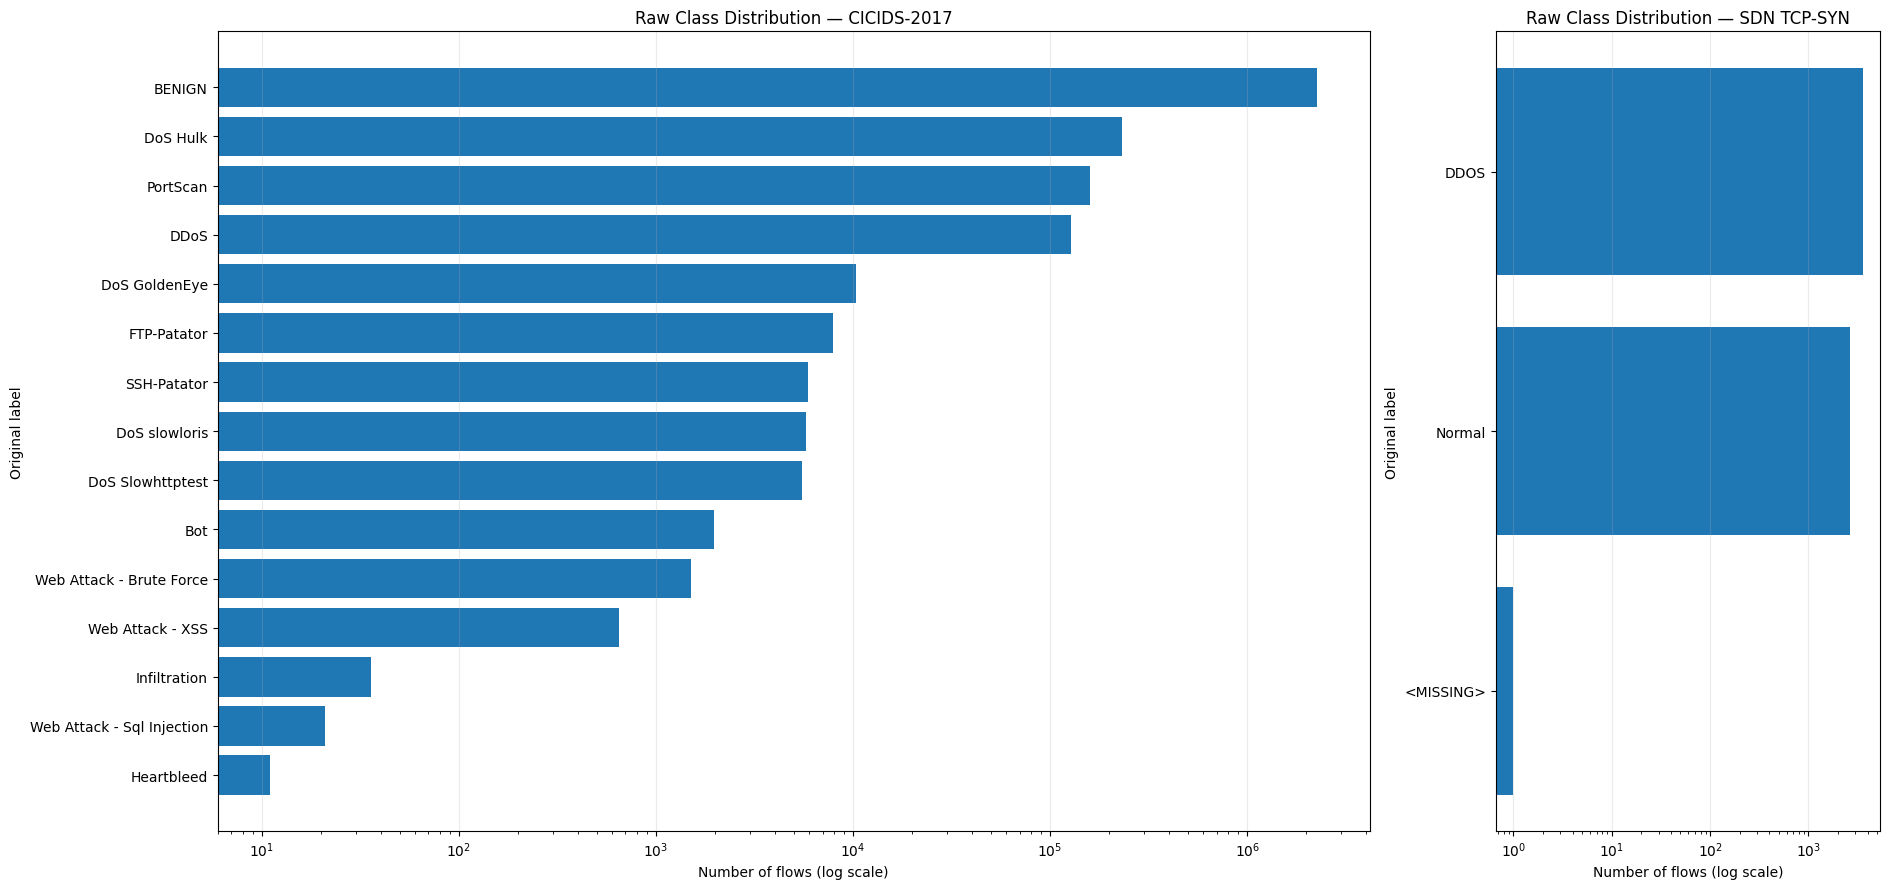

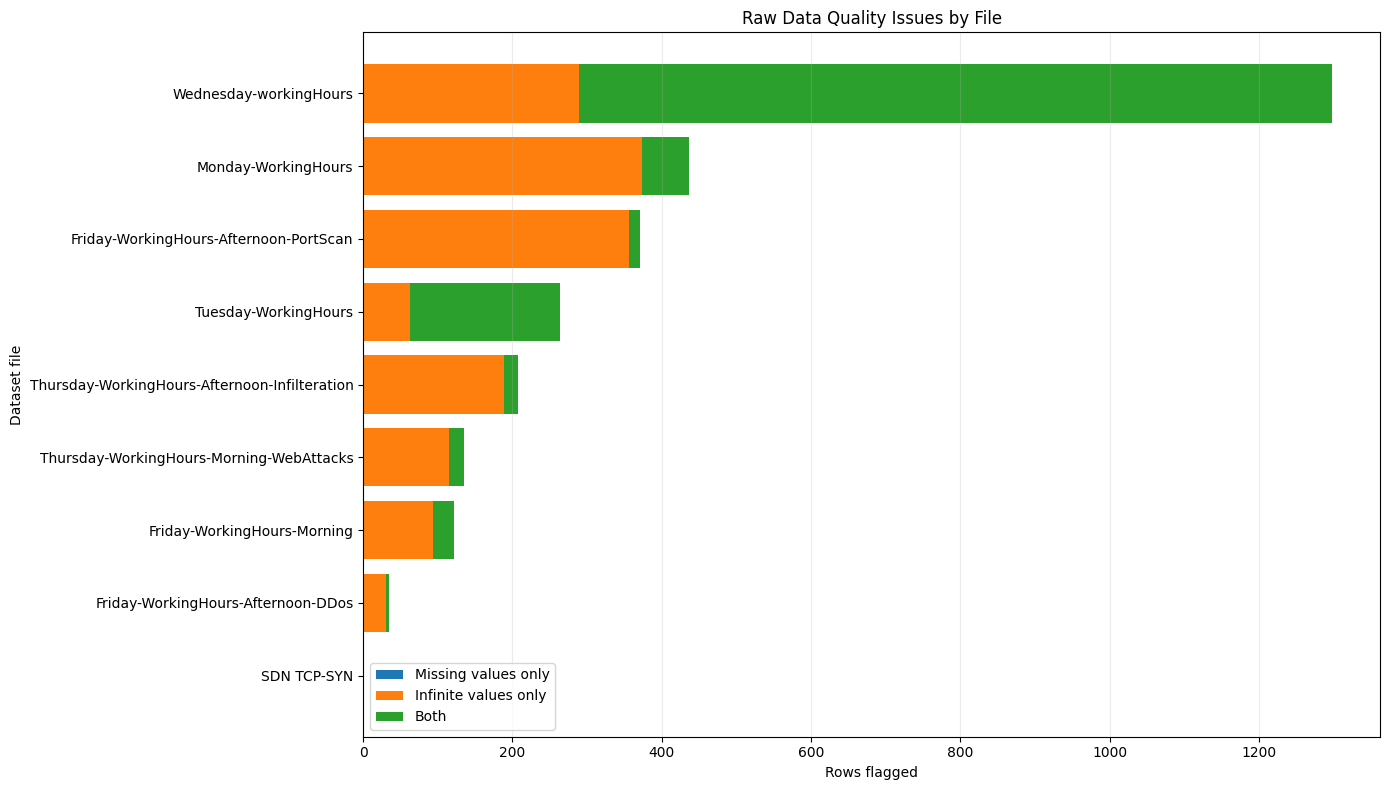

Figures saved to: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\results\figures
Supporting tables saved to: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\results\metrics


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)


# 1. Aggregate raw label counts across files.
labels = raw_label_distribution.copy()

labels["label_display"] = (
    labels["label"]
    .astype(str)
    .str.strip()
    .str.replace("\ufffd", "-", regex=False)
)

class_counts = (
    labels.groupby(
        ["dataset", "label_display"],
        as_index=False,
    )["count"]
    .sum()
)

class_counts.to_csv(
    METRICS_DIR / "raw_class_counts.csv",
    index=False,
)


# Plot each dataset separately because their sizes differ greatly.
fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 9),
    gridspec_kw={"width_ratios": [3, 1]},
)

for ax, dataset_name in zip(
    axes,
    ["CICIDS-2017", "SDN TCP-SYN"],
):
    data = (
        class_counts[class_counts["dataset"] == dataset_name]
        .sort_values("count")
    )

    ax.barh(data["label_display"], data["count"])
    ax.set_xscale("log")
    ax.set_title(f"Raw Class Distribution — {dataset_name}")
    ax.set_xlabel("Number of flows (log scale)")
    ax.set_ylabel("Original label")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "raw_class_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# 2. Visualize row-level data-quality issues.
quality_plot = quality_audit.copy()

quality_plot["file_display"] = (
    quality_plot["file"]
    .str.replace(".pcap_ISCX.csv", "", regex=False)
    .str.replace("TCP-SYNC DATASET.csv", "SDN TCP-SYN", regex=False)
)

quality_plot["missing_only"] = (
    quality_plot["rows_with_missing"]
    - quality_plot["rows_with_both"]
)

quality_plot["infinite_only"] = (
    quality_plot["rows_with_infinity"]
    - quality_plot["rows_with_both"]
)

quality_plot = quality_plot.sort_values(
    "rows_to_remove_for_quality"
)

quality_plot[
    [
        "dataset", "file", "missing_only",
        "infinite_only", "rows_with_both",
        "rows_to_remove_for_quality",
    ]
].to_csv(
    METRICS_DIR / "raw_data_quality.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(14, 8))

ax.barh(
    quality_plot["file_display"],
    quality_plot["missing_only"],
    label="Missing values only",
)

ax.barh(
    quality_plot["file_display"],
    quality_plot["infinite_only"],
    left=quality_plot["missing_only"],
    label="Infinite values only",
)

ax.barh(
    quality_plot["file_display"],
    quality_plot["rows_with_both"],
    left=(
        quality_plot["missing_only"]
        + quality_plot["infinite_only"]
    ),
    label="Both",
)

ax.set_title("Raw Data Quality Issues by File")
ax.set_xlabel("Rows flagged")
ax.set_ylabel("Dataset file")
ax.legend()
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "raw_data_quality.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Figures saved to:", FIGURES_DIR)
print("Supporting tables saved to:", METRICS_DIR)

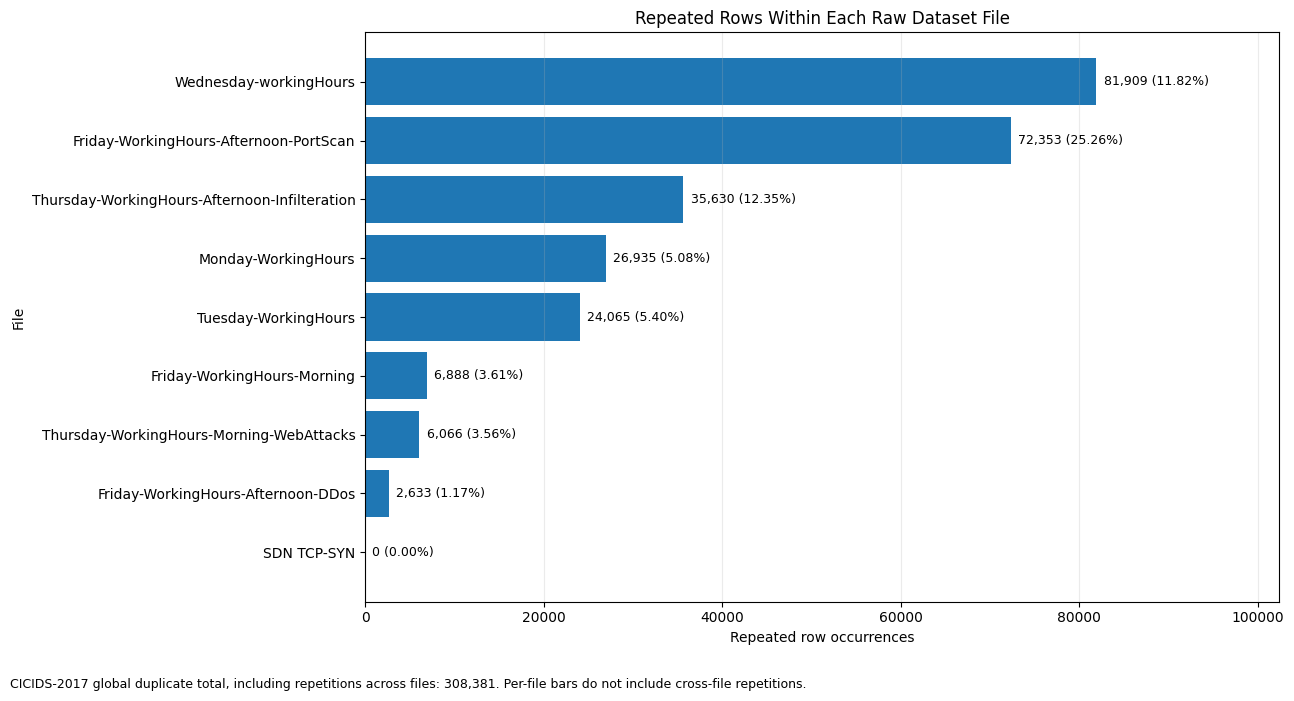

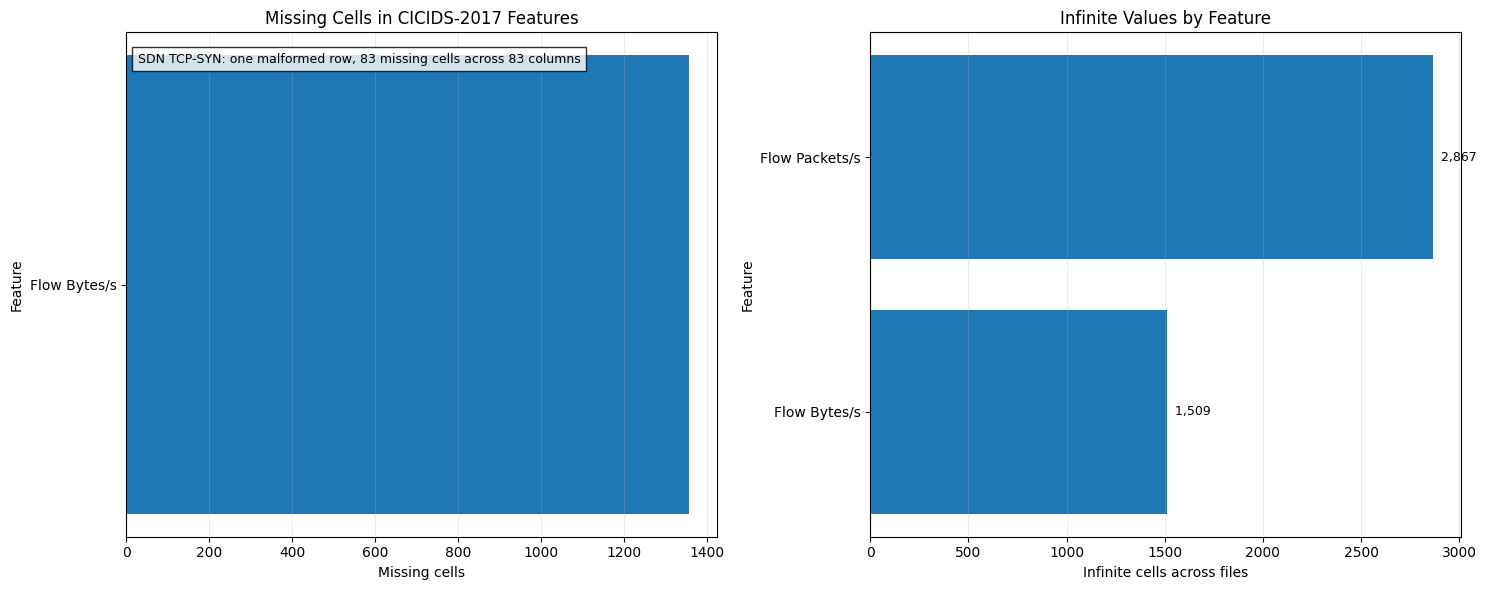

Saved duplicate visualization and supporting table.
Saved feature-quality visualization and supporting tables.
Figure directory: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\results\figures
Metrics directory: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\results\metrics


In [14]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Reuse the audit tables created earlier.
required = [
    "duplicate_summary",
    "global_duplicates",
    "missing_details",
    "infinite_details",
]

missing_variables = [name for name in required if name not in globals()]
if missing_variables:
    raise RuntimeError(
        f"Run the corresponding audit cells first: {missing_variables}"
    )

FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 1. DUPLICATE ROWS BY FILE
# ============================================================

duplicates = duplicate_summary.copy()

duplicates["duplicate_pct"] = (
    duplicates["duplicate_rows"]
    / duplicates["rows_scanned"]
    * 100
)

duplicates["file_display"] = (
    duplicates["file"]
    .str.replace(".pcap_ISCX.csv", "", regex=False)
    .str.replace("TCP-SYNC DATASET.csv", "SDN TCP-SYN", regex=False)
)

duplicates = duplicates.sort_values("duplicate_rows")

duplicates.to_csv(
    METRICS_DIR / "raw_duplicate_counts.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    duplicates["file_display"],
    duplicates["duplicate_rows"],
)

max_duplicates = max(duplicates["duplicate_rows"].max(), 1)

for bar, (_, row) in zip(bars, duplicates.iterrows()):
    count = int(row["duplicate_rows"])
    percentage = row["duplicate_pct"]

    ax.text(
        bar.get_width() + max_duplicates * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({percentage:.2f}%)",
        va="center",
        fontsize=9,
    )

ax.set_xlim(0, max_duplicates * 1.25)
ax.set_title("Repeated Rows Within Each Raw Dataset File")
ax.set_xlabel("Repeated row occurrences")
ax.set_ylabel("File")
ax.grid(axis="x", alpha=0.25)

cicids_global = global_duplicates.loc[
    global_duplicates["dataset"] == "CICIDS-2017",
    "duplicate_rows_to_remove",
]

if not cicids_global.empty:
    fig.text(
        0.01,
        0.01,
        "CICIDS-2017 global duplicate total, including repetitions "
        f"across files: {int(cicids_global.iloc[0]):,}. "
        "Per-file bars do not include cross-file repetitions.",
        fontsize=9,
    )

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    FIGURES_DIR / "raw_duplicate_analysis.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


# ============================================================
# 2. FEATURE-LEVEL MISSING AND INFINITE VALUES
# ============================================================

missing = missing_details.copy()
infinite = infinite_details.copy()

missing["column_clean"] = missing["column"].astype(str).str.strip()
infinite["column_clean"] = infinite["column"].astype(str).str.strip()

missing_by_feature = (
    missing.groupby(
        ["dataset", "column_clean"],
        as_index=False,
    )["missing_count"]
    .sum()
    .rename(columns={"column_clean": "feature"})
)

infinite_by_feature = (
    infinite.groupby(
        ["dataset", "column_clean"],
        as_index=False,
    )["infinite_count"]
    .sum()
    .rename(columns={"column_clean": "feature"})
)

# Export every affected feature, not only the ones plotted.
missing_by_feature.to_csv(
    METRICS_DIR / "raw_missing_by_feature.csv",
    index=False,
)

infinite_by_feature.to_csv(
    METRICS_DIR / "raw_infinite_by_feature.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Missing values: plot recurrently affected features.
# The SDN missing values are handled separately below because
# 83 missing cells belong to one malformed record.
cicids_missing = (
    missing_by_feature[
        (missing_by_feature["dataset"] == "CICIDS-2017")
        & (missing_by_feature["missing_count"] > 1)
    ]
    .sort_values("missing_count")
)

if not cicids_missing.empty:
    axes[0].barh(
        cicids_missing["feature"],
        cicids_missing["missing_count"],
    )

axes[0].set_title("Missing Cells in CICIDS-2017 Features")
axes[0].set_xlabel("Missing cells")
axes[0].set_ylabel("Feature")
axes[0].grid(axis="x", alpha=0.25)

sdn_missing_cells = int(
    missing_by_feature.loc[
        missing_by_feature["dataset"] == "SDN TCP-SYN",
        "missing_count",
    ].sum()
)

sdn_missing_columns = int(
    missing_by_feature.loc[
        missing_by_feature["dataset"] == "SDN TCP-SYN",
        "feature",
    ].nunique()
)

axes[0].text(
    0.02,
    0.96,
    f"SDN TCP-SYN: one malformed row, "
    f"{sdn_missing_cells} missing cells across "
    f"{sdn_missing_columns} columns",
    transform=axes[0].transAxes,
    va="top",
    fontsize=9,
    bbox={"facecolor": "white", "alpha": 0.8},
)

# Infinite values: aggregate feature counts across files.
infinite_totals = (
    infinite_by_feature
    .groupby("feature", as_index=False)["infinite_count"]
    .sum()
    .sort_values("infinite_count")
)

axes[1].barh(
    infinite_totals["feature"],
    infinite_totals["infinite_count"],
)

axes[1].set_title("Infinite Values by Feature")
axes[1].set_xlabel("Infinite cells across files")
axes[1].set_ylabel("Feature")
axes[1].grid(axis="x", alpha=0.25)

for _, row in infinite_totals.iterrows():
    axes[1].text(
        row["infinite_count"],
        row["feature"],
        f"  {int(row['infinite_count']):,}",
        va="center",
        fontsize=9,
    )

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "raw_feature_quality.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Saved duplicate visualization and supporting table.")
print("Saved feature-quality visualization and supporting tables.")
print("Figure directory:", FIGURES_DIR)
print("Metrics directory:", METRICS_DIR)

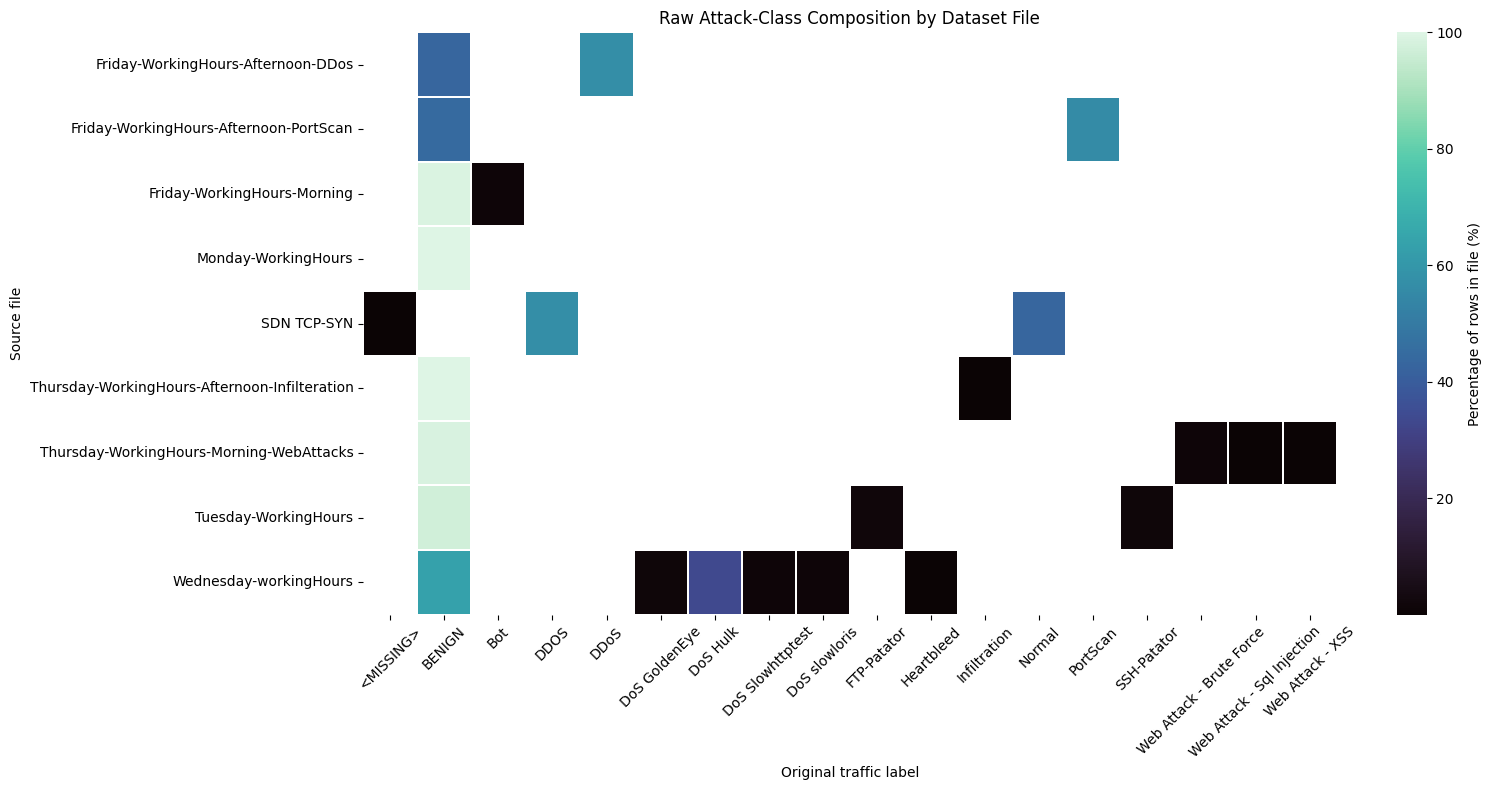

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare labels for display without changing the source data.
plot_data = raw_label_distribution.copy()

plot_data["label"] = (
    plot_data["label"]
    .astype(str)
    .str.strip()
    .str.replace("\ufffd", "-", regex=False)
)

plot_data["file_display"] = (
    plot_data["file"]
    .str.replace(".pcap_ISCX.csv", "", regex=False)
    .str.replace("TCP-SYNC DATASET.csv", "SDN TCP-SYN", regex=False)
)

# Count each class within each source file.
class_matrix = plot_data.pivot_table(
    index="file_display",
    columns="label",
    values="count",
    aggfunc="sum",
    fill_value=0,
)

# Express every cell as a percentage of that file's rows.
class_percentages = (
    class_matrix
    .div(class_matrix.sum(axis=1), axis=0)
    * 100
)

# Save the data underlying the visualization.
class_percentages.to_csv(
    METRICS_DIR / "raw_class_percentage_by_file.csv"
)

fig, ax = plt.subplots(figsize=(16, 8))

sns.heatmap(
    class_percentages,
    cmap="mako",
    linewidths=0.3,
    mask=class_percentages.eq(0),
    cbar_kws={"label": "Percentage of rows in file (%)"},
    ax=ax,
)

ax.set_title("Raw Attack-Class Composition by Dataset File")
ax.set_xlabel("Original traffic label")
ax.set_ylabel("Source file")
ax.tick_params(axis="x", labelrotation=45)
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "raw_class_composition_heatmap.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path

CHUNK_SIZE = 100_000
CICIDS_SAMPLE_PER_CHUNK = 2_000
RANDOM_SEED = 42

# Metadata and redundant columns are excluded from numerical profiling.
excluded_columns = {
    "label", "flow id",
    "src ip", "dst ip", "source ip", "destination ip",
    "src port", "dst port", "source port", "destination port",
    "timestamp", "protocol",
    "fwd header length.1",
}

feature_columns_by_dataset = {}
sampled_data = {}

for dataset_name, directory in DATASET_DIRS.items():
    files = sorted(directory.glob("*.csv"))
    parts = []
    feature_columns = None

    for file_path in files:
        header = pd.read_csv(
            file_path, nrows=0, encoding="utf-8-sig"
        ).columns.tolist()

        label_columns = [
            c for c in header if c.strip().casefold() == "label"
        ]

        if len(label_columns) != 1:
            raise ValueError(
                f"Expected exactly one label column in {file_path.name}"
            )

        label_col = label_columns[0]
        features = [
            c for c in header
            if c.strip().casefold() not in excluded_columns
        ]

        if feature_columns is None:
            feature_columns = [c.strip() for c in features]

        usecols = features + [label_col]

        for chunk_number, chunk in enumerate(pd.read_csv(
            file_path,
            usecols=usecols,
            chunksize=CHUNK_SIZE,
            low_memory=False,
            encoding="utf-8-sig",
        )):
            sample_size = (
                CICIDS_SAMPLE_PER_CHUNK
                if dataset_name == "CICIDS-2017"
                else len(chunk)
            )
            sample_size = min(sample_size, len(chunk))

            sample = chunk.sample(
                n=sample_size,
                random_state=RANDOM_SEED + chunk_number,
            )

            labels = sample[label_col].astype("string").str.strip()

            X = sample[features].apply(
                pd.to_numeric, errors="coerce"
            )
            X.columns = [c.strip() for c in X.columns]

            X["label"] = labels.to_numpy()
            X["source_file"] = file_path.name
            parts.append(X)

    sampled_data[dataset_name] = pd.concat(
        parts, ignore_index=True
    )
    feature_columns_by_dataset[dataset_name] = feature_columns

    print(
        f"{dataset_name}: profiled "
        f"{len(sampled_data[dataset_name]):,} sampled rows; "
        f"{len(feature_columns)} candidate features"
    )


# Profile distributions using finite values only.
# Missing and infinite values are reported separately.
profile_records = []

for dataset_name, sample in sampled_data.items():
    for feature in feature_columns_by_dataset[dataset_name]:
        values = pd.to_numeric(
            sample[feature], errors="coerce"
        ).to_numpy(dtype=float)

        finite = values[np.isfinite(values)]

        if len(finite) == 0:
            profile_records.append({
                "dataset": dataset_name,
                "feature": feature,
                "finite_count": 0,
                "missing_pct": 100 * np.isnan(values).mean(),
                "infinite_pct": 100 * np.isinf(values).mean(),
                "zero_pct": np.nan,
                "skewness": np.nan,
                "median": np.nan,
                "p99": np.nan,
                "p99_abs": np.nan,
                "max_abs": np.nan,
            })
            continue

        series = pd.Series(finite)

        profile_records.append({
            "dataset": dataset_name,
            "feature": feature,
            "finite_count": len(finite),
            "missing_pct": 100 * np.isnan(values).mean(),
            "infinite_pct": 100 * np.isinf(values).mean(),
            "zero_pct": 100 * (finite == 0).mean(),
            "skewness": series.skew(),
            "median": series.median(),
            "p99": series.quantile(0.99),
            "p99_abs": np.quantile(np.abs(finite), 0.99),
            "max_abs": np.max(np.abs(finite)),
        })

numeric_profile = pd.DataFrame(profile_records)

METRICS_DIR.mkdir(parents=True, exist_ok=True)
numeric_profile.to_csv(
    METRICS_DIR / "raw_numeric_profile.csv",
    index=False,
)

# Show the most skewed features and the most zero-heavy features.
for dataset_name in DATASET_DIRS:
    result = numeric_profile[
        numeric_profile["dataset"] == dataset_name
    ].copy()

    print(f"\n{dataset_name}: most skewed features")
    display(
        result.assign(
            abs_skew=result["skewness"].abs()
        )
        .sort_values("abs_skew", ascending=False)
        .head(12)
        .drop(columns="abs_skew")
        .round(3)
    )

    print(f"\n{dataset_name}: most zero-heavy features")
    display(
        result.sort_values("zero_pct", ascending=False)
        .head(12)
        .round(3)
    )

print("\nFull profile saved to:", METRICS_DIR / "raw_numeric_profile.csv")

CICIDS-2017: profiled 62,000 sampled rows; 76 candidate features
SDN TCP-SYN: profiled 6,234 sampled rows; 76 candidate features

CICIDS-2017: most skewed features


,dataset,feature,finite_count,missing_pct,infinite_pct,zero_pct,skewness,median,p99,p99_abs,max_abs
66,CICIDS-2017,act_data_pkt_fwd,62000,0.0,0.0,34.127,245.687,1.0,27.00,27.00,200511.0
33,CICIDS-2017,Fwd Header Length,62000,0.0,0.0,0.056,182.322,64.0,1328.00,1328.00,4401888.0
63,CICIDS-2017,Subflow Bwd Bytes,62000,0.0,0.0,24.898,182.038,124.0,72352.39,72352.39,617658527.0
4,CICIDS-2017,Total Length of Bwd Packets,62000,0.0,0.0,24.898,182.015,124.0,72352.39,72352.39,617658527.0
60,CICIDS-2017,Subflow Fwd Packets,62000,0.0,0.0,0.000,181.960,2.0,48.01,48.01,209916.0
1,CICIDS-2017,Total Fwd Packets,62000,0.0,0.0,0.000,181.960,2.0,48.01,48.01,209916.0
2,CICIDS-2017,Total Backward Packets,62000,0.0,0.0,15.410,181.926,2.0,57.00,57.00,280292.0
62,CICIDS-2017,Subflow Bwd Packets,62000,0.0,0.0,15.410,181.926,2.0,57.00,57.00,280292.0
34,CICIDS-2017,Bwd Header Length,62000,0.0,0.0,15.410,181.844,40.0,1480.00,1480.00,5605840.0
61,CICIDS-2017,Subflow Fwd Bytes,62000,0.0,0.0,15.923,145.245,62.0,11282.00,11282.00,1246041.0



CICIDS-2017: most zero-heavy features


,dataset,feature,finite_count,missing_pct,infinite_pct,zero_pct,skewness,median,p99,p99_abs,max_abs
54,CICIDS-2017,Fwd Avg Bytes/Bulk,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
55,CICIDS-2017,Fwd Avg Packets/Bulk,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
30,CICIDS-2017,Bwd PSH Flags,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
32,CICIDS-2017,Bwd URG Flags,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
56,CICIDS-2017,Fwd Avg Bulk Rate,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
57,CICIDS-2017,Bwd Avg Bytes/Bulk,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
59,CICIDS-2017,Bwd Avg Bulk Rate,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
58,CICIDS-2017,Bwd Avg Packets/Bulk,62000,0.0,0.0,100.000,0.000,0.0,0.0,0.0,0.0
48,CICIDS-2017,CWE Flag Count,62000,0.0,0.0,99.992,111.345,0.0,0.0,0.0,1.0
31,CICIDS-2017,Fwd URG Flags,62000,0.0,0.0,99.992,111.345,0.0,0.0,0.0,1.0



SDN TCP-SYN: most skewed features


,dataset,feature,finite_count,missing_pct,infinite_pct,zero_pct,skewness,median,p99,p99_abs,max_abs
120,SDN TCP-SYN,RST Flag Cnt,6233,0.016,0.0,99.984,78.949,0.000,0.000000e+00,0.000000e+00,1.0
104,SDN TCP-SYN,Bwd IAT Min,6233,0.016,0.0,22.894,55.666,46.000,1.187240e+05,1.187240e+05,45100000.0
147,SDN TCP-SYN,Active Min,6233,0.016,0.0,84.807,53.472,0.000,4.212756e+06,4.212756e+06,108000000.0
144,SDN TCP-SYN,Active Mean,6233,0.016,0.0,84.807,42.230,0.000,5.835112e+06,5.835112e+06,108000000.0
89,SDN TCP-SYN,Flow Byts/s,6233,0.016,0.0,65.971,24.323,0.000,9.636943e+04,9.636943e+04,15500000.0
146,SDN TCP-SYN,Active Max,6233,0.016,0.0,84.807,22.215,0.000,9.974201e+06,9.974201e+06,108000000.0
111,SDN TCP-SYN,Fwd Pkts/s,6233,0.016,0.0,8.439,16.714,9433.962,3.703704e+04,3.703704e+04,500000.0
94,SDN TCP-SYN,Flow IAT Min,6233,0.016,0.0,0.882,14.123,38.000,1.526800e+07,1.526800e+07,107000000.0
145,SDN TCP-SYN,Active Std,6233,0.016,0.0,93.021,12.889,0.000,3.413217e+06,3.413217e+06,20500000.0
79,SDN TCP-SYN,TotLen Fwd Pkts,6233,0.016,0.0,73.319,12.823,0.000,2.370148e+04,2.370148e+04,183486.0



SDN TCP-SYN: most zero-heavy features


,dataset,feature,finite_count,missing_pct,infinite_pct,zero_pct,skewness,median,p99,p99_abs,max_abs
123,SDN TCP-SYN,URG Flag Cnt,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
133,SDN TCP-SYN,Bwd Byts/b Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
130,SDN TCP-SYN,Fwd Byts/b Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
131,SDN TCP-SYN,Fwd Pkts/b Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
135,SDN TCP-SYN,Bwd Blk Rate Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
143,SDN TCP-SYN,Fwd Seg Size Min,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
125,SDN TCP-SYN,ECE Flag Cnt,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
134,SDN TCP-SYN,Bwd Pkts/b Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
132,SDN TCP-SYN,Fwd Blk Rate Avg,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0
105,SDN TCP-SYN,Fwd PSH Flags,6233,0.016,0.0,100.0,0.0,0.0,0.0,0.0,0.0



Full profile saved to: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\results\metrics\raw_numeric_profile.csv


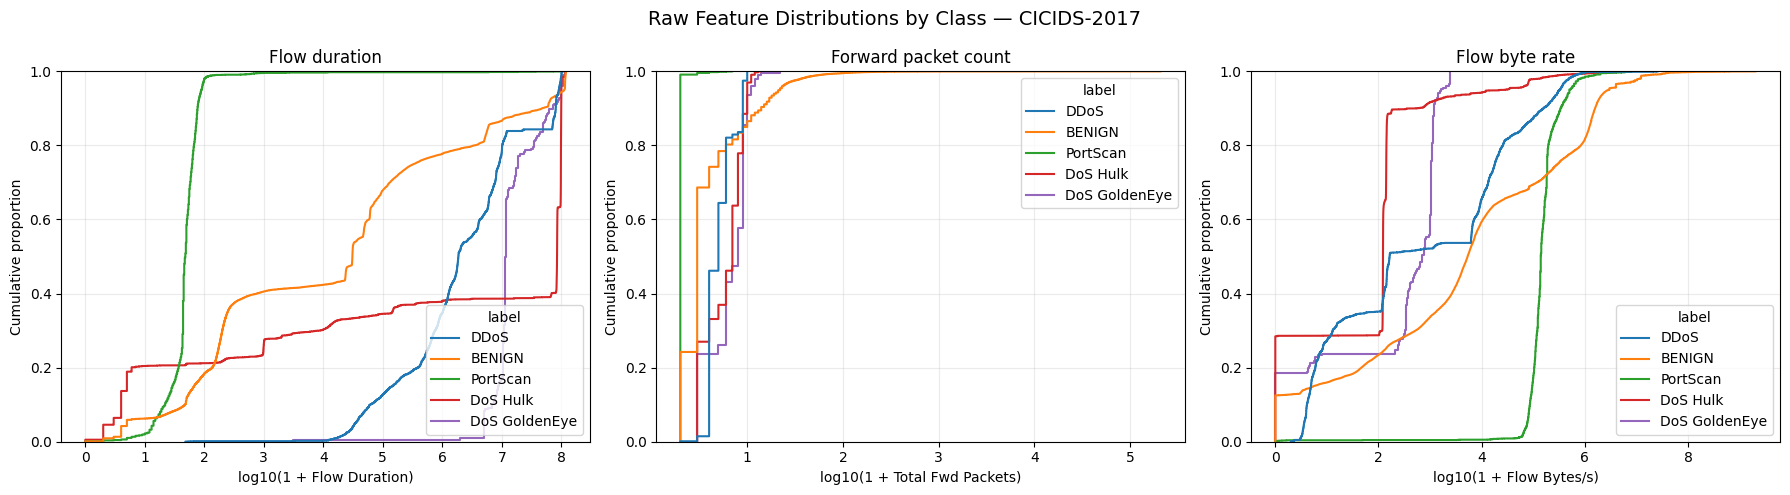

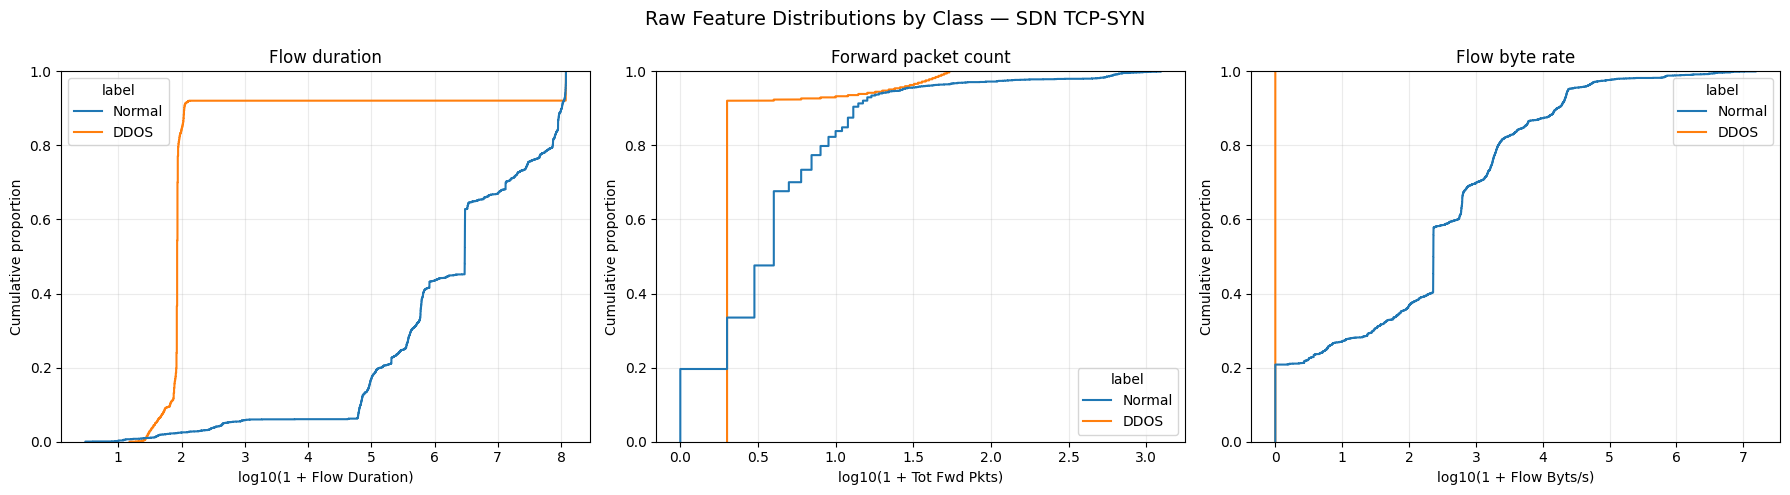

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Semantically corresponding features in the two datasets.
feature_mapping = {
    "Flow duration": {
        "CICIDS-2017": "Flow Duration",
        "SDN TCP-SYN": "Flow Duration",
    },
    "Forward packet count": {
        "CICIDS-2017": "Total Fwd Packets",
        "SDN TCP-SYN": "Tot Fwd Pkts",
    },
    "Flow byte rate": {
        "CICIDS-2017": "Flow Bytes/s",
        "SDN TCP-SYN": "Flow Byts/s",
    },
}

for dataset_name, data in sampled_data.items():
    data = data.loc[data["label"].notna()].copy()

    # Show benign traffic plus the four most frequent attack labels
    # for CICIDS-2017; show both labels for SDN TCP-SYN.
    if dataset_name == "CICIDS-2017":
        counts = data["label"].value_counts()
        selected_labels = []

        if "BENIGN" in counts.index:
            selected_labels.append("BENIGN")

        selected_labels.extend(
            label for label in counts.index
            if label != "BENIGN"
        )
        selected_labels = selected_labels[:5]
    else:
        selected_labels = [
            label for label in ["Normal", "DDOS"]
            if label in data["label"].values
        ]

    plot_data = data[data["label"].isin(selected_labels)]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (feature_title, mapping) in zip(
        axes, feature_mapping.items()
    ):
        column = mapping[dataset_name]

        if column not in plot_data.columns:
            ax.set_visible(False)
            print(f"Feature unavailable: {dataset_name} / {column}")
            continue

        values = pd.to_numeric(
            plot_data[column], errors="coerce"
        ).to_numpy(dtype=float)

        # Log transformation is used for visualization only.
        # Negative, infinite, and missing values are excluded
        # from this particular plot and are not deleted from data.
        valid = np.isfinite(values) & (values >= 0)

        chart = plot_data.loc[valid, ["label"]].copy()
        chart["log10_value"] = np.log10(1 + values[valid])

        sns.ecdfplot(
            data=chart,
            x="log10_value",
            hue="label",
            ax=ax,
        )

        ax.set_title(feature_title)
        ax.set_xlabel(f"log10(1 + {column})")
        ax.set_ylabel("Cumulative proportion")
        ax.grid(alpha=0.25)

    fig.suptitle(
        f"Raw Feature Distributions by Class — {dataset_name}",
        fontsize=14,
    )
    fig.tight_layout()

    output_name = dataset_name.lower().replace(" ", "_").replace("-", "_")
    fig.savefig(
        FIGURES_DIR / f"raw_feature_ecdf_{output_name}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()

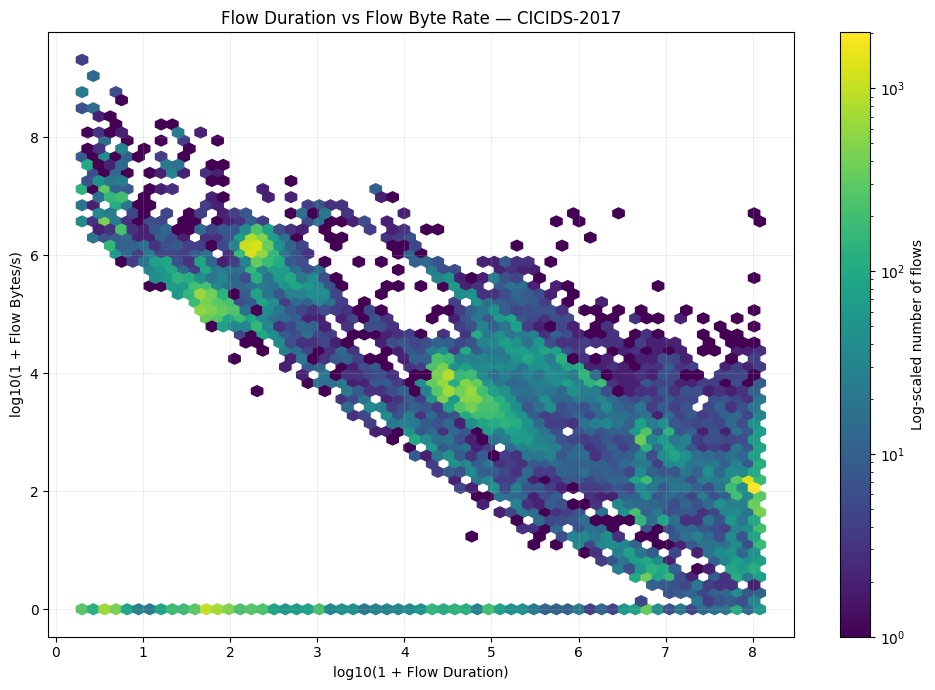

In [18]:
cicids = sampled_data["CICIDS-2017"]

duration = pd.to_numeric(
    cicids["Flow Duration"], errors="coerce"
).to_numpy(dtype=float)

byte_rate = pd.to_numeric(
    cicids["Flow Bytes/s"], errors="coerce"
).to_numpy(dtype=float)

valid = (
    np.isfinite(duration)
    & np.isfinite(byte_rate)
    & (duration >= 0)
    & (byte_rate >= 0)
)

x = np.log10(1 + duration[valid])
y = np.log10(1 + byte_rate[valid])

fig, ax = plt.subplots(figsize=(10, 7))

hexes = ax.hexbin(
    x,
    y,
    gridsize=60,
    mincnt=1,
    bins="log",
)

colorbar = fig.colorbar(hexes, ax=ax)
colorbar.set_label("Log-scaled number of flows")

ax.set_title("Flow Duration vs Flow Byte Rate — CICIDS-2017")
ax.set_xlabel("log10(1 + Flow Duration)")
ax.set_ylabel("log10(1 + Flow Bytes/s)")
ax.grid(alpha=0.2)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "raw_duration_vs_byte_rate_hexbin.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

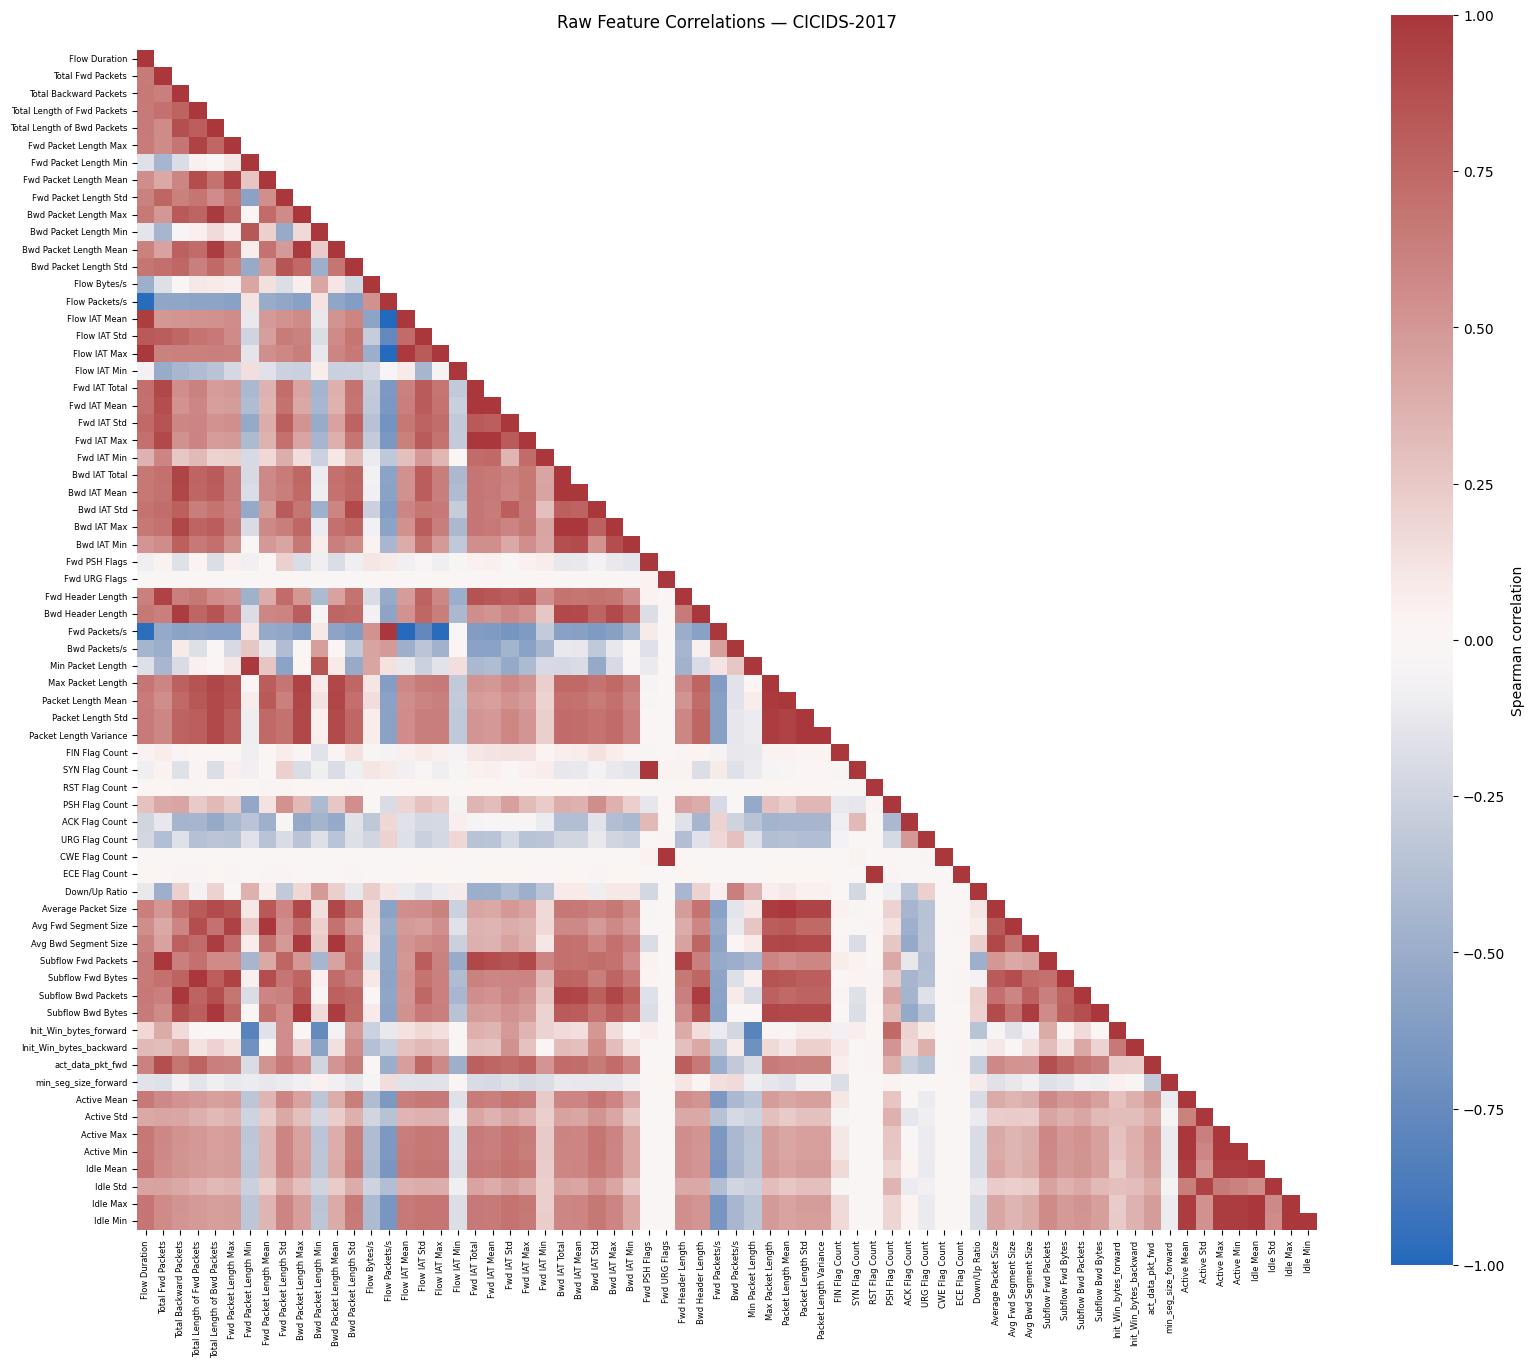

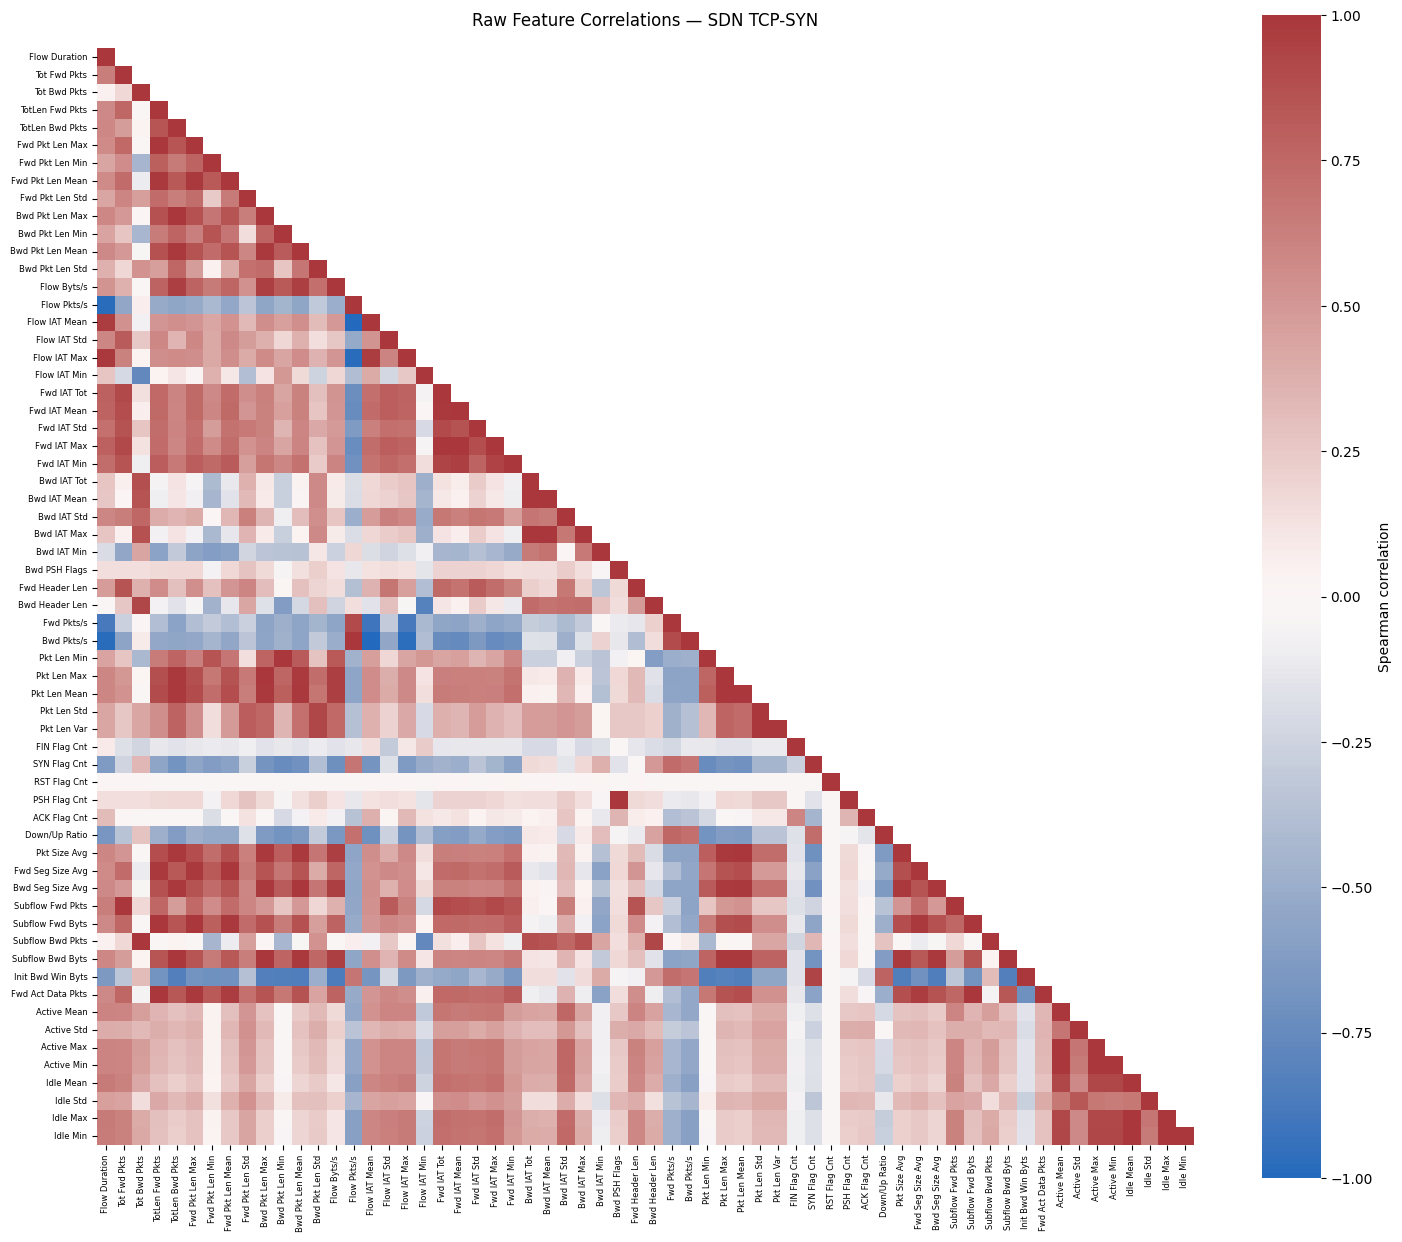

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

correlation_matrices = {}

for dataset_name, data in sampled_data.items():
    # Use numeric feature columns only, excluding labels and metadata.
    feature_columns = feature_columns_by_dataset[dataset_name]
    X = data[feature_columns].apply(pd.to_numeric, errors="coerce")

    # Treat positive and negative infinity as missing for correlation.
    X = X.replace([np.inf, -np.inf], np.nan)

    # Remove features that are constant in the visualization sample.
    variable_columns = [
        column
        for column in X.columns
        if X[column].nunique(dropna=True) > 1
    ]
    X = X[variable_columns]

    # Spearman correlation uses pairwise available observations.
    correlation = X.corr(
        method="spearman",
        min_periods=500,
    )

    # Exclude features whose correlations could not be calculated.
    valid_columns = correlation.columns[
        correlation.notna().any(axis=0)
    ]
    correlation = correlation.loc[
        valid_columns, valid_columns
    ]

    if correlation.empty:
        print(f"No valid correlations for {dataset_name}")
        continue

    correlation_matrices[dataset_name] = correlation

    # Export the full correlation matrix.
    filename = (
        dataset_name.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    correlation.to_csv(
        METRICS_DIR / f"raw_spearman_correlation_{filename}.csv"
    )

    # Mask the upper triangle to avoid showing the same
    # correlation twice.
    mask = np.triu(
        np.ones(correlation.shape, dtype=bool),
        k=1,
    )

    fig_size = max(14, len(correlation.columns) * 0.24)

    fig, ax = plt.subplots(
        figsize=(fig_size, fig_size * 0.85)
    )

    sns.heatmap(
        correlation,
        mask=mask,
        cmap="vlag",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0,
        xticklabels=True,
        yticklabels=True,
        cbar_kws={"label": "Spearman correlation"},
        ax=ax,
    )

    ax.set_title(
        f"Raw Feature Correlations — {dataset_name}",
        pad=16,
    )
    ax.tick_params(axis="x", labelrotation=90, labelsize=6)
    ax.tick_params(axis="y", labelrotation=0, labelsize=6)

    plt.tight_layout()

    fig.savefig(
        FIGURES_DIR / f"raw_spearman_correlation_{filename}.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

In [20]:
import pandas as pd

def norm(name):
    return str(name).strip().casefold()


# SDN TCP-SYN name -> equivalent CICIDS-2017 name
SDN_TO_CICIDS = {
    "Tot Fwd Pkts": "Total Fwd Packets",
    "Tot Bwd Pkts": "Total Backward Packets",
    "TotLen Fwd Pkts": "Total Length of Fwd Packets",
    "TotLen Bwd Pkts": "Total Length of Bwd Packets",

    "Fwd Pkt Len Max": "Fwd Packet Length Max",
    "Fwd Pkt Len Min": "Fwd Packet Length Min",
    "Fwd Pkt Len Mean": "Fwd Packet Length Mean",
    "Fwd Pkt Len Std": "Fwd Packet Length Std",
    "Bwd Pkt Len Max": "Bwd Packet Length Max",
    "Bwd Pkt Len Min": "Bwd Packet Length Min",
    "Bwd Pkt Len Mean": "Bwd Packet Length Mean",
    "Bwd Pkt Len Std": "Bwd Packet Length Std",

    "Flow Byts/s": "Flow Bytes/s",
    "Flow Pkts/s": "Flow Packets/s",
    "Fwd IAT Tot": "Fwd IAT Total",
    "Bwd IAT Tot": "Bwd IAT Total",

    "Fwd Header Len": "Fwd Header Length",
    "Bwd Header Len": "Bwd Header Length",
    "Fwd Pkts/s": "Fwd Packets/s",
    "Bwd Pkts/s": "Bwd Packets/s",

    "Pkt Len Max": "Max Packet Length",
    "Pkt Len Min": "Min Packet Length",
    "Pkt Len Mean": "Packet Length Mean",
    "Pkt Len Std": "Packet Length Std",
    "Pkt Len Var": "Packet Length Variance",

    "FIN Flag Cnt": "FIN Flag Count",
    "SYN Flag Cnt": "SYN Flag Count",
    "RST Flag Cnt": "RST Flag Count",
    "PSH Flag Cnt": "PSH Flag Count",
    "ACK Flag Cnt": "ACK Flag Count",
    "URG Flag Cnt": "URG Flag Count",
    "ECE Flag Cnt": "ECE Flag Count",
    "CWE Flag Cnt": "CWE Flag Count",

    "Pkt Size Avg": "Average Packet Size",
    "Fwd Seg Size Avg": "Avg Fwd Segment Size",
    "Bwd Seg Size Avg": "Avg Bwd Segment Size",

    "Subflow Fwd Byts": "Subflow Fwd Bytes",
    "Subflow Bwd Byts": "Subflow Bwd Bytes",
    "Subflow Fwd Pkts": "Subflow Fwd Packets",
    "Subflow Bwd Pkts": "Subflow Bwd Packets",

    "Init Fwd Win Byts": "Init_Win_bytes_forward",
    "Init Bwd Win Byts": "Init_Win_bytes_backward",
    "Fwd Act Data Pkts": "act_data_pkt_fwd",
    "Fwd Seg Size Min": "min_seg_size_forward",

    "Fwd Byts/b Avg": "Fwd Avg Bytes/Bulk",
    "Fwd Pkts/b Avg": "Fwd Avg Packets/Bulk",
    "Fwd Blk Rate Avg": "Fwd Avg Bulk Rate",
    "Bwd Byts/b Avg": "Bwd Avg Bytes/Bulk",
    "Bwd Pkts/b Avg": "Bwd Avg Packets/Bulk",
    "Bwd Blk Rate Avg": "Bwd Avg Bulk Rate",

    "Dst Port": "Destination Port",
}

aliases = {
    norm(source): norm(target)
    for source, target in SDN_TO_CICIDS.items()
}

# These columns are identifiers, metadata, targets, or redundant.
excluded = {
    "label",
    "flow id",
    "src ip", "dst ip",
    "source ip", "destination ip",
    "src port", "dst port",
    "source port", "destination port",
    "timestamp", "protocol",
    "fwd header length.1",
}

cicids_path = next(DATASET_DIRS["CICIDS-2017"].glob("*.csv"))
sdn_path = next(DATASET_DIRS["SDN TCP-SYN"].glob("*.csv"))

cicids_columns = pd.read_csv(cicids_path, nrows=0).columns.tolist()
sdn_columns = pd.read_csv(sdn_path, nrows=0).columns.tolist()

cicids_features = {
    norm(column)
    for column in cicids_columns
    if norm(column) not in excluded
}

sdn_features = {
    aliases.get(norm(column), norm(column))
    for column in sdn_columns
    if norm(column) not in excluded
}

print("CICIDS candidate features:", len(cicids_features))
print("SDN candidate features after mapping:", len(sdn_features))
print("Common features:", len(cicids_features & sdn_features))

print("\nOnly in CICIDS-2017:")
print(sorted(cicids_features - sdn_features))

print("\nOnly in SDN TCP-SYN after mapping:")
print(sorted(sdn_features - cicids_features))

CICIDS candidate features: 76
SDN candidate features after mapping: 76
Common features: 76

Only in CICIDS-2017:
[]

Only in SDN TCP-SYN after mapping:
[]


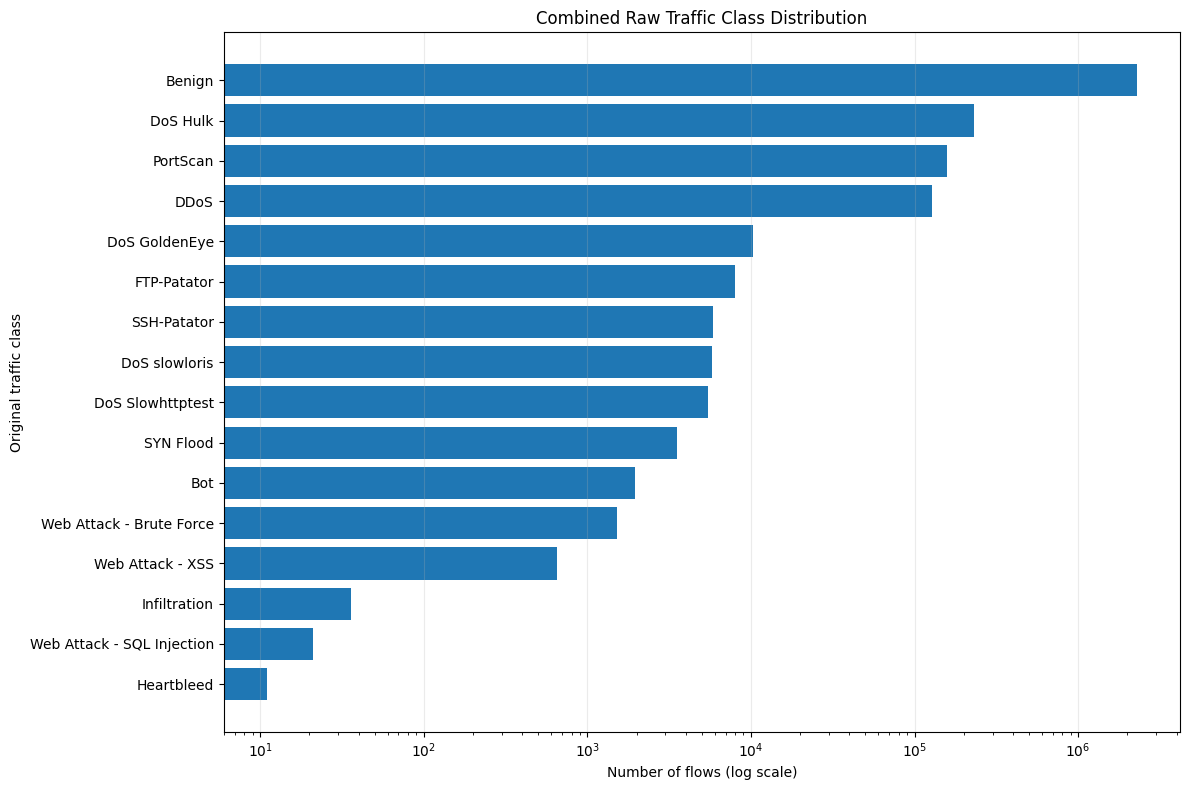

Missing-label rows excluded from class counts: 1
Raw class count table saved.


In [21]:
import pandas as pd
import matplotlib.pyplot as plt


def standardize_raw_label(dataset, label):
    """Standardize labels for reporting without modifying source data."""
    label = str(label).strip()

    if label == "<MISSING>":
        return None

    if dataset == "SDN TCP-SYN":
        if label.casefold() == "normal":
            return "Benign"
        if label.casefold() == "ddos":
            return "SYN Flood"

    label = label.replace("\ufffd", "-")
    lower = label.casefold()

    if lower == "benign":
        return "Benign"

    if "web attack" in lower:
        if "brute force" in lower:
            return "Web Attack - Brute Force"
        if "sql injection" in lower:
            return "Web Attack - SQL Injection"
        if "xss" in lower:
            return "Web Attack - XSS"

    return label


combined_raw_counts = raw_label_distribution.copy()

combined_raw_counts["class"] = combined_raw_counts.apply(
    lambda row: standardize_raw_label(
        row["dataset"], row["label"]
    ),
    axis=1,
)

# Missing labels are data-quality issues, not a traffic class.
missing_label_rows = int(
    combined_raw_counts["class"].isna().sum()
)

combined_raw_counts = combined_raw_counts.dropna(subset=["class"])

combined_raw_counts = (
    combined_raw_counts.groupby("class", as_index=False)["count"]
    .sum()
    .sort_values("count")
)

combined_raw_counts.to_csv(
    METRICS_DIR / "combined_raw_class_counts.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    combined_raw_counts["class"],
    combined_raw_counts["count"],
)

ax.set_xscale("log")
ax.set_xlabel("Number of flows (log scale)")
ax.set_ylabel("Original traffic class")
ax.set_title("Combined Raw Traffic Class Distribution")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "combined_raw_class_distribution.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Missing-label rows excluded from class counts:", missing_label_rows)
print("Raw class count table saved.")

In [22]:
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# 1. Validate notebook state and create export directory
# ============================================================

required_variables = [
    "PROJECT_ROOT",
    "inventory",
    "raw_label_distribution",
    "quality_audit",
    "missing_details",
    "infinite_details",
    "duplicate_summary",
    "global_duplicates",
    "numeric_profile",
    "sampled_data",
    "correlation_matrices",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run all preceding cells in 01_raw_data_analysis.ipynb first. "
        f"Missing variables: {missing_variables}"
    )

EXPORT_DIR = PROJECT_ROOT / "exports" / "phase01_raw"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


def save_csv(dataframe, filename):
    """Save a visualization-ready CSV and report its size."""
    path = EXPORT_DIR / filename
    dataframe.to_csv(path, index=False, encoding="utf-8")
    print(f"Saved: {path.name} ({path.stat().st_size / 1024:.1f} KB)")


def normalize(name):
    return str(name).strip().casefold()


# ============================================================
# 2. Standardize labels for display, preserving raw labels
# ============================================================

def display_raw_label(dataset, value):
    if pd.isna(value):
        return "Missing label (not a class)"

    raw = str(value).strip()

    if raw in {"", "<MISSING>"}:
        return "Missing label (not a class)"

    label = raw.replace("\ufffd", "-")
    key = label.casefold()

    if dataset == "SDN TCP-SYN":
        if key == "normal":
            return "Benign"
        if key == "ddos":
            return "SYN Flood"

    label_map = {
        "benign": "Benign",
        "ddos": "DDoS",
        "portscan": "PortScan",
        "dos hulk": "DoS Hulk",
        "dos goldeneye": "DoS GoldenEye",
        "dos slowloris": "DoS slowloris",
        "dos slowhttptest": "DoS Slowhttptest",
        "ftp-patator": "FTP-Patator",
        "ssh-patator": "SSH-Patator",
        "bot": "Bot",
        "heartbleed": "Heartbleed",
        "infiltration": "Infiltration",
        "web attack - brute force": "Web Attack - Brute Force",
        "web attack - sql injection": "Web Attack - SQL Injection",
        "web attack - xss": "Web Attack - XSS",
    }

    return label_map.get(key, label)


# ============================================================
# 3. File inventory
# ============================================================

inventory_export = inventory.drop(
    columns=["path"], errors="ignore"
).copy()

inventory_export = inventory_export.rename(
    columns={"size_MB": "size_mb"}
)

relative_directories = {
    "CICIDS-2017": "Datasets/CICIDS2017",
    "SDN TCP-SYN": "Datasets/SDN_TCP_SYN",
}

inventory_export["relative_path"] = inventory_export.apply(
    lambda row: (
        f"{relative_directories[row['dataset']]}/{row['file']}"
    ),
    axis=1,
)

save_csv(inventory_export, "raw_file_inventory.csv")


# ============================================================
# 4. Raw class counts and percentages by file
# ============================================================

class_counts = raw_label_distribution.copy()

class_counts = class_counts.rename(
    columns={"label": "raw_label"}
)

class_counts["display_class"] = class_counts.apply(
    lambda row: display_raw_label(
        row["dataset"], row["raw_label"]
    ),
    axis=1,
)

class_counts["raw_label"] = class_counts["raw_label"].astype(str)

file_totals = (
    class_counts.groupby(
        ["dataset", "file"], as_index=False
    )["count"]
    .sum()
    .rename(columns={"count": "file_rows"})
)

class_counts = class_counts.merge(
    file_totals,
    on=["dataset", "file"],
    how="left",
)

class_counts["percentage_of_file"] = (
    100 * class_counts["count"] / class_counts["file_rows"]
)

class_counts.to_csv(
    EXPORT_DIR / "raw_class_counts_by_file.csv",
    index=False,
    encoding="utf-8",
)
print("Saved: raw_class_counts_by_file.csv")

# Combined counts retain the distinct original web-attack categories.
combined_class_counts = (
    class_counts[
        class_counts["display_class"] != "Missing label (not a class)"
    ]
    .groupby("display_class", as_index=False)["count"]
    .sum()
    .rename(columns={
        "display_class": "class",
        "count": "flows",
    })
    .sort_values("flows", ascending=False)
)

save_csv(combined_class_counts, "raw_class_counts_combined.csv")


# ============================================================
# 5. Row-level data-quality summary by file
# ============================================================

quality_export = quality_audit.copy()

quality_export["missing_only_rows"] = (
    quality_export["rows_with_missing"]
    - quality_export["rows_with_both"]
)

quality_export["infinite_only_rows"] = (
    quality_export["rows_with_infinity"]
    - quality_export["rows_with_both"]
)

quality_export["rows_affected_pct"] = (
    100
    * quality_export["rows_to_remove_for_quality"]
    / quality_export["total_rows"]
)

save_csv(quality_export, "raw_quality_by_file.csv")


# ============================================================
# 6. Missing and infinite cells by file and column
# ============================================================

missing_export = missing_details.rename(
    columns={
        "column": "feature",
        "missing_count": "missing_cells",
    }
).copy()

infinite_export = infinite_details.rename(
    columns={
        "column": "feature",
        "infinite_count": "infinite_cells",
    }
).copy()

missing_export["feature"] = (
    missing_export["feature"].astype(str).str.strip()
)

infinite_export["feature"] = (
    infinite_export["feature"].astype(str).str.strip()
)

column_quality = missing_export.merge(
    infinite_export,
    on=["dataset", "file", "feature"],
    how="outer",
)

for column in ["missing_cells", "infinite_cells"]:
    column_quality[column] = (
        column_quality[column].fillna(0).astype(int)
    )

row_totals = quality_audit[
    ["dataset", "file", "total_rows"]
]

column_quality = column_quality.merge(
    row_totals,
    on=["dataset", "file"],
    how="left",
)

column_quality["missing_pct_of_rows"] = (
    100 * column_quality["missing_cells"]
    / column_quality["total_rows"]
)

column_quality["infinite_pct_of_rows"] = (
    100 * column_quality["infinite_cells"]
    / column_quality["total_rows"]
)

save_csv(column_quality, "raw_quality_by_column.csv")


# ============================================================
# 7. Duplicate statistics
# ============================================================

duplicates_by_file = duplicate_summary.copy()

duplicates_by_file["duplicate_pct"] = (
    100
    * duplicates_by_file["duplicate_rows"]
    / duplicates_by_file["rows_scanned"]
)

save_csv(duplicates_by_file, "raw_duplicates_by_file.csv")

duplicates_global = global_duplicates.copy()

duplicates_global["duplicate_pct"] = (
    100
    * duplicates_global["duplicate_rows_to_remove"]
    / duplicates_global["total_rows"]
)

save_csv(duplicates_global, "raw_duplicates_global.csv")


# ============================================================
# 8. Numeric feature profile
# ============================================================

save_csv(numeric_profile, "raw_numeric_feature_profile.csv")


# ============================================================
# 9. Correlation matrices: wide and long formats
# ============================================================

correlation_frames = []

for dataset, correlation in correlation_matrices.items():
    suffix = (
        dataset.lower()
        .replace("-", "_")
        .replace(" ", "_")
    )

    wide = correlation.copy()
    wide.index.name = "feature"

    wide_path = EXPORT_DIR / f"raw_spearman_{suffix}_wide.csv"
    wide.to_csv(wide_path, encoding="utf-8")
    print(f"Saved: {wide_path.name}")

    long = (
        correlation
        .rename_axis(index="feature_x", columns="feature_y")
        .stack(dropna=False)
        .rename("spearman_correlation")
        .reset_index()
    )

    long.insert(0, "dataset", dataset)
    correlation_frames.append(long)

correlation_long = pd.concat(
    correlation_frames, ignore_index=True
)

save_csv(correlation_long, "raw_spearman_correlations_long.csv")


# ============================================================
# 10. Export the exact sample used for feature-distribution plots
# ============================================================

# Shared feature concepts, using each dataset's original column names.
feature_specs = {
    "flow_duration": {
        "CICIDS-2017": "Flow Duration",
        "SDN TCP-SYN": "Flow Duration",
    },
    "forward_packet_count": {
        "CICIDS-2017": "Total Fwd Packets",
        "SDN TCP-SYN": "Tot Fwd Pkts",
    },
    "flow_byte_rate": {
        "CICIDS-2017": "Flow Bytes/s",
        "SDN TCP-SYN": "Flow Byts/s",
    },
}

sample_frames = []

for dataset, data in sampled_data.items():
    normalized_lookup = {
        normalize(column): column
        for column in data.columns
    }

    if "label" not in normalized_lookup:
        raise ValueError(f"Sampled data for {dataset} has no label column.")

    label_column = normalized_lookup["label"]

    if "source_file" not in normalized_lookup:
        raise ValueError(
            f"Sampled data for {dataset} has no source_file column."
        )

    source_column = normalized_lookup["source_file"]

    frame = pd.DataFrame({
        "dataset": dataset,
        "sample_id": [
            f"{dataset.replace(' ', '_')}__{i:07d}"
            for i in range(len(data))
        ],
        "source_file": data[source_column].astype(str).to_numpy(),
        "raw_label": data[label_column].astype("string").fillna(
            "<MISSING>"
        ).astype(str).to_numpy(),
    })

    frame["display_class"] = [
        display_raw_label(dataset, label)
        for label in frame["raw_label"]
    ]

    for output_name, mapping in feature_specs.items():
        source_feature = mapping[dataset]
        actual_column = normalized_lookup.get(
            normalize(source_feature)
        )

        if actual_column is None:
            raise ValueError(
                f"Feature {source_feature!r} is missing in {dataset}."
            )

        values = pd.to_numeric(
            data[actual_column], errors="coerce"
        ).to_numpy(dtype=float)

        # Infinity is represented as blank for BI visualization.
        # The separate quality tables retain the invalid-value counts.
        values[~np.isfinite(values)] = np.nan
        frame[output_name] = values

    sample_frames.append(frame)

distribution_sample_wide = pd.concat(
    sample_frames, ignore_index=True
)

save_csv(
    distribution_sample_wide,
    "raw_feature_distribution_sample_wide.csv",
)

distribution_sample_long = distribution_sample_wide.melt(
    id_vars=[
        "dataset", "sample_id", "source_file",
        "raw_label", "display_class",
    ],
    value_vars=list(feature_specs.keys()),
    var_name="feature",
    value_name="value",
)

feature_titles = {
    "flow_duration": "Flow duration",
    "forward_packet_count": "Forward packet count",
    "flow_byte_rate": "Flow byte rate",
}

distribution_sample_long["feature"] = (
    distribution_sample_long["feature"].map(feature_titles)
)

save_csv(
    distribution_sample_long,
    "raw_feature_distribution_sample_long.csv",
)


# ============================================================
# 11. Write a data dictionary for Tableau / Power BI
# ============================================================

readme = """ClearFlow — Phase 1 raw-data exports
======================================

All CSV files in this folder are generated by
notebooks/01_raw_data_analysis.ipynb.

Files
-----

raw_file_inventory.csv
    Input file paths (repository-relative) and sizes.

raw_class_counts_by_file.csv
    Raw label counts and percentages within each file.
    raw_label preserves the observed label.
    display_class harmonizes labels for visual display.
    The three web attack types remain separate.

raw_class_counts_combined.csv
    Total flow counts by harmonized display class.
    Missing labels are excluded; Heartbleed and Infiltration remain.

raw_quality_by_file.csv
    Row counts affected by missing values, infinities, or both.

raw_quality_by_column.csv
    Missing and infinite cell counts per original file and column.
    These are cell counts, not distinct-row counts.

raw_duplicates_by_file.csv
    Exact repeated rows within each individual source file.

raw_duplicates_global.csv
    Exact repeated complete-row patterns across each dataset.
    These are not the reduced model-feature duplicate counts.

raw_numeric_feature_profile.csv
    Numeric feature statistics computed on a reproducible sample.

raw_spearman_*_wide.csv
    Spearman correlation matrices, suitable for matrix/heatmap views.

raw_spearman_correlations_long.csv
    Correlations in dataset, feature_x, feature_y, value format.

raw_feature_distribution_sample_wide.csv
    Sampled flows with dataset, source file, raw label, display class,
    flow duration, forward packet count, and flow byte rate.
    Use this wide table for hexbin/scatter plots.

raw_feature_distribution_sample_long.csv
    The same sampled values in feature/value format, useful for
    ECDF and distribution charts.

Sampling
-------

CICIDS-2017 distribution plots use up to 2,000 sampled rows per
100,000-row chunk, with a fixed random seed. This is a visualization
sample, not the modeling dataset. SDN TCP-SYN uses all its rows.

Non-finite sampled feature values are stored as blanks for BI tools.
Quality tables separately document the missing and infinite values.

For logarithmic plots using log10(1 + x), filter to finite, nonnegative
values. Original raw CSV files are not modified.

Regenerate these exports by running the notebook cells in order.
"""

readme_path = EXPORT_DIR / "README.txt"
readme_path.write_text(readme, encoding="utf-8")

print("\nPhase 1 export complete.")
print("Export directory:", EXPORT_DIR)
print("CSV files:", len(list(EXPORT_DIR.glob("*.csv"))))
print("README:", readme_path)

Saved: raw_file_inventory.csv (1.1 KB)
Saved: raw_class_counts_by_file.csv
Saved: raw_class_counts_combined.csv (0.3 KB)
Saved: raw_quality_by_file.csv (1.1 KB)
Saved: raw_quality_by_column.csv (8.5 KB)
Saved: raw_duplicates_by_file.csv (0.9 KB)
Saved: raw_duplicates_global.csv (0.2 KB)
Saved: raw_numeric_feature_profile.csv (17.5 KB)
Saved: raw_spearman_cicids_2017_wide.csv
Saved: raw_spearman_sdn_tcp_syn_wide.csv
Saved: raw_spearman_correlations_long.csv (519.5 KB)


C:\Users\arhat\AppData\Local\Temp\ipykernel_23368\516591637.py:322: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=False)
C:\Users\arhat\AppData\Local\Temp\ipykernel_23368\516591637.py:322: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(dropna=False)


Saved: raw_feature_distribution_sample_wide.csv (7454.7 KB)
Saved: raw_feature_distribution_sample_long.csv (22658.3 KB)

Phase 1 export complete.
Export directory: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\exports\phase01_raw
CSV files: 13
README: C:\Users\arhat\OneDrive\Desktop\Amrita\sem5\DV\Project\ClearFlow\exports\phase01_raw\README.txt
